# Member 1 – Dataset, Annotation & Gold-Label Verification
**Project:** Classification of Bangla Telecom and Mobile-Banking Customer-Care Utterances Using Classical NLP Techniques

This notebook rechecks Member 1's dataset and annotation work using the group's real CSV files. It does **not** create labels or change the gold dataset automatically.

### What this notebook checks
1. Required columns, row counts, missing values and duplicate IDs/text.
2. The six allowed labels and final class distribution.
3. Consistency between `gold_labels_final.csv` and `master_sentences.csv`.
4. Annotation changes and adjudication records.
5. Cohen's Kappa, if the independent annotator-label file(s) are supplied.
6. Exportable verification reports and a final pass/warning summary.

**Important:** Upload the actual latest project files. Do not use screenshots or previously printed tables as substitutes for CSV files. The notebook preserves originals and writes separate report files.

## 0. Files to prepare before running

Upload these files when prompted:

| Required? | File | Why it is needed |
|---|---|---|
| Required | `gold_labels_final.csv` | Final adjudicated gold labels; expected columns include `sentence_id`, `sentence`, `label`. |
| Required | `master_sentences.csv` | Master extracted sentence list; expected columns include `sentence_id`, `sentence`, `doc_id`, `owner`. |
| Strongly recommended | `final_adjudication_decisions.csv` | Records uncertain cases and final adjudication decisions. |
| Required for a fresh Kappa calculation | Independent annotation CSV | Must contain the same sentence IDs and one label column per annotator, or separate annotator files. |
| Optional | Annotation guidelines (`.pdf`, `.docx`, `.txt`) | Used for checking that documented class definitions and procedure match the project. |

**Kappa warning:** If you only have the final gold labels, Cohen's Kappa between annotators cannot be recalculated from them. Kappa needs the original independent labels from both annotators before adjudication. Do not calculate Kappa by comparing an annotator's labels with the final gold labels and call it inter-annotator agreement.

In [ ]:
# Install only the small set of packages needed for verification.
%pip -q install pandas numpy scikit-learn matplotlib

In [ ]:
from pathlib import Path
import os, re, json, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score, accuracy_score, confusion_matrix, classification_report
from IPython.display import display

SEED = 42
EXPECTED_CLASSES = [
    "mobile_money",
    "bank_service",
    "telecom_sim_pack",
    "security_otp",
    "complaint_helpline",
    "generic_dialogue",
]
MIN_EXPECTED_ROWS = 2000

print("Environment ready.")
print("Expected labels:", EXPECTED_CLASSES)

Environment ready.
Expected labels: ['mobile_money', 'bank_service', 'telecom_sim_pack', 'security_otp', 'complaint_helpline', 'generic_dialogue']


## 1. Upload the project files

Upload the CSVs listed in Section 0. You may upload several files together. The notebook identifies files by filename; if your filenames differ, edit the mapping cell below.

In [ ]:
from google.colab import files

uploaded = files.upload()
print("\nUploaded files:")
for name in uploaded:
    print(" -", name)

Saving gold_labels_final.csv to gold_labels_final.csv
Saving final_adjudication_decisions.csv to final_adjudication_decisions.csv
Saving M3_independent.csv to M3_independent.csv
Saving M2_independent.csv to M2_independent.csv
Saving M1_independent.csv to M1_independent.csv
Saving master_sentences.csv to master_sentences.csv

Uploaded files:
 - gold_labels_final.csv
 - final_adjudication_decisions.csv
 - M3_independent.csv
 - M2_independent.csv
 - M1_independent.csv
 - master_sentences.csv


## 2. Identify and load the files

The default filenames below match the names used in the group's saved project materials. If your actual file has a different name, change the value in the mapping dictionary.

In [ ]:
import pandas as pd

files = {
    "M1": "M1_independent.csv",
    "M2": "M2_independent.csv",
    "M3": "M3_independent.csv"
}

for name, filename in files.items():
    df = pd.read_csv(filename)

    print(f"\n{name}: {filename}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))


M1: M1_independent.csv
Shape: (961, 5)
Columns: ['sentence_id', 'sentence', 'label', 'uncertain', 'note']


,sentence_id,sentence,label,uncertain,note
0,S0242,আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড এক চার দুই...,security_otp,False,NaN
1,S0853,"দুঃখিত, আপনার বাংলালিংক সিম রিপ্লেসমেন্টের জন্...",complaint_helpline,False,NaN
2,S0437,"চিন্তা করবেন না, আপনার বিকাশ অ্যাকাউন্টের লাস্...",mobile_money,False,NaN



M2: M2_independent.csv
Shape: (961, 5)
Columns: ['sentence_id', 'sentence', 'label', 'uncertain', 'note']


,sentence_id,sentence,label,uncertain,note
0,S0895,আপনার অভিযোগ নম্বরটি কি আট শূন্য এক দুই চার দি...,complaint_helpline,NaN,NaN
1,S0896,"চিন্তা করবেন না, যদি অ্যাকাউন্টে অচেনা লেনদেন ...",security_otp,NaN,NaN
2,S0897,"ধন্যবাদ, আপনি কি একই নম্বরে একাধিকবার রিচার্জ ...",telecom_sim_pack,NaN,NaN



M3: M3_independent.csv
Shape: (961, 5)
Columns: ['sentence_id', 'sentence', 'label', 'uncertain', 'note']


,sentence_id,sentence,label,uncertain,note
0,S0001,"দুঃখিত, আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড পা...",security_otp,no,নিরাপত্তা যাচাই
1,S0002,"ঠিক আছে, আপনি কি আগামীকাল সকাল এই সমস্যাটি প্র...",generic_dialogue,yes,Human review recommended: General conversation...
2,S0003,ডিপিএস কিস্তি পনেরো টাকা জমা হয়েছে।,bank_service,no,ডিপিএস; কিস্তি


In [ ]:
# EDIT ONLY IF YOUR UPLOADED FILES HAVE DIFFERENT NAMES.
FILE_MAP = {
    "gold": "gold_labels_final.csv",
    "master": "master_sentences.csv",
    "adjudication": "final_adjudication_decisions.csv",
    # Add your independent annotator file(s) below if available.
    # Example: "annotations": "independent_annotations.csv"
    "annotations": None,
}

def load_csv_if_present(key):
    filename = FILE_MAP.get(key)
    if not filename:
        print(f"{key}: not configured (optional unless noted).")
        return None
    path = Path(filename)
    if not path.exists():
        print(f"WARNING: {filename} was not uploaded.")
        return None
    df = pd.read_csv(path, keep_default_na=False)
    print(f"{key}: loaded {filename} | shape={df.shape}")
    return df

gold = load_csv_if_present("gold")
master = load_csv_if_present("master")
adjudication = load_csv_if_present("adjudication")
annotations = load_csv_if_present("annotations")

if gold is None:
    raise FileNotFoundError("Upload gold_labels_final.csv and set FILE_MAP['gold'] correctly.")
if master is None:
    raise FileNotFoundError("Upload master_sentences.csv and set FILE_MAP['master'] correctly.")

print("\nGold columns:", gold.columns.tolist())
print("Master columns:", master.columns.tolist())
if adjudication is not None:
    print("Adjudication columns:", adjudication.columns.tolist())
if annotations is not None:
    print("Annotation columns:", annotations.columns.tolist())

gold: loaded gold_labels_final.csv | shape=(2682, 4)
master: loaded master_sentences.csv | shape=(2682, 4)
adjudication: loaded final_adjudication_decisions.csv | shape=(16, 10)
annotations: not configured (optional unless noted).

Gold columns: ['sentence_id', 'sentence', 'label', 'label_source']
Master columns: ['sentence_id', 'sentence', 'doc_id', 'owner']
Adjudication columns: ['sentence_id', 'sentence', 'owner', 'label_owner', 'neighbour', 'label_neighbour', 'final_label', 'reason', 'confidence', 'decision_source']


## 3. Validate the final gold-label file

**Why:** The gold-label file is the source of truth for model training. It should contain one row per unique sentence ID, a non-empty sentence, and exactly one of the six approved labels.

In [ ]:
required_gold = {"sentence_id", "sentence", "label"}
missing = required_gold - set(gold.columns)
gold_checks = []

def record_check(name, passed, detail):
    gold_checks.append({"check": name, "status": "PASS" if passed else "FAIL", "details": str(detail)})

record_check("Required columns", not missing, f"missing={sorted(missing)}")
record_check("At least 2,000 labelled rows", len(gold) >= MIN_EXPECTED_ROWS, f"rows={len(gold)}")
if not missing:
    record_check("No blank sentence IDs", gold["sentence_id"].astype(str).str.strip().ne("").all(),
                 f"blank IDs={(gold['sentence_id'].astype(str).str.strip() == '').sum()}")
    record_check("Unique sentence IDs", gold["sentence_id"].is_unique,
                 f"duplicate IDs={gold['sentence_id'].duplicated().sum()}")
    record_check("No blank sentences", gold["sentence"].astype(str).str.strip().ne("").all(),
                 f"blank sentences={(gold['sentence'].astype(str).str.strip() == '').sum()}")
    labels = set(gold["label"].astype(str).str.strip())
    record_check("Only six permitted labels", labels <= set(EXPECTED_CLASSES),
                 f"unexpected={sorted(labels - set(EXPECTED_CLASSES))}")
    record_check("All six labels represented", set(EXPECTED_CLASSES) <= labels,
                 f"missing classes={sorted(set(EXPECTED_CLASSES) - labels)}")

gold_check_df = pd.DataFrame(gold_checks)
display(gold_check_df)

,check,status,details
0,Required columns,PASS,missing=[]
1,"At least 2,000 labelled rows",PASS,rows=2682
2,No blank sentence IDs,PASS,blank IDs=0
3,Unique sentence IDs,PASS,duplicate IDs=0
4,No blank sentences,PASS,blank sentences=0
5,Only six permitted labels,PASS,unexpected=[]
6,All six labels represented,PASS,missing classes=[]


## 4. Check class distribution and imbalance

**Why:** The final class counts must come from the actual gold-label CSV, not the proposal's preliminary keyword estimates. This cell calculates counts, percentages and the largest-to-smallest class ratio.

,class,count,percentage
0,mobile_money,512,19.09
1,bank_service,311,11.60
2,telecom_sim_pack,511,19.05
3,security_otp,574,21.40
4,complaint_helpline,377,14.06
5,generic_dialogue,397,14.80


Total labelled rows: 2,682
Unique labelled sentences: 2,682
Largest/smallest class ratio: 1.85


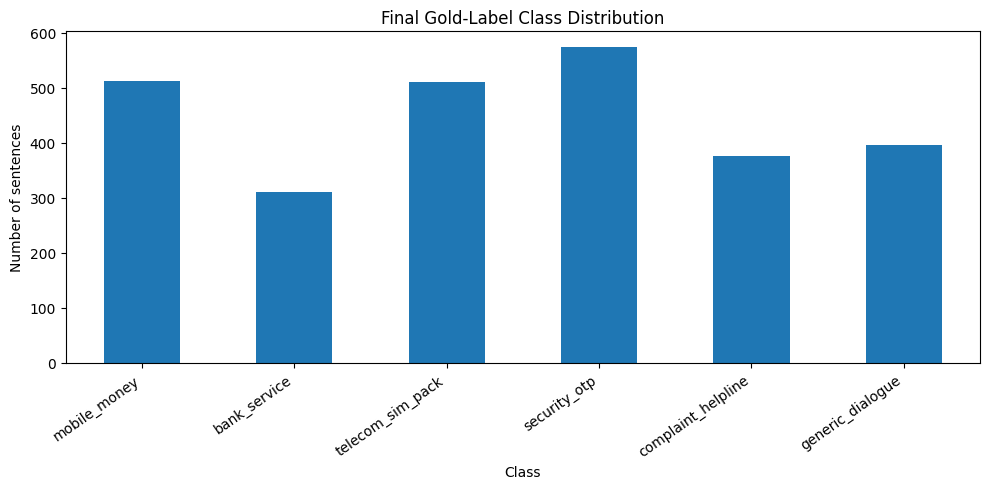

In [ ]:
if {"sentence_id", "sentence", "label"} <= set(gold.columns):
    gold["label_clean"] = gold["label"].astype(str).str.strip()
    class_counts = (gold["label_clean"].value_counts()
                    .reindex(EXPECTED_CLASSES, fill_value=0)
                    .rename_axis("class").reset_index(name="count"))
    class_counts["percentage"] = (class_counts["count"] / len(gold) * 100).round(2)
    display(class_counts)
    nonzero = class_counts.loc[class_counts["count"] > 0, "count"]
    ratio = nonzero.max() / nonzero.min() if len(nonzero) == len(EXPECTED_CLASSES) else np.nan
    print(f"Total labelled rows: {len(gold):,}")
    print(f"Unique labelled sentences: {gold['sentence'].nunique():,}")
    print(f"Largest/smallest class ratio: {ratio:.2f}" if np.isfinite(ratio) else "Cannot calculate ratio: one or more classes are empty.")

    ax = class_counts.plot(kind="bar", x="class", y="count", legend=False, figsize=(10, 5))
    ax.set_title("Final Gold-Label Class Distribution")
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of sentences")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Cannot calculate distribution until required gold columns are fixed.")

## 5. Check the master sentence file

**Why:** The master file should preserve the extracted sentence inventory and source-document IDs. We check required columns, missing values, repeated IDs, repeated text, and document coverage. Repeated sentence text is not automatically an error in the master file because the extraction stage may retain repeated occurrences; compare it with the unique gold-label file separately.

In [ ]:
required_master = {"sentence_id", "sentence", "doc_id", "owner"}
missing_master = required_master - set(master.columns)
master_checks = []
record = lambda n, p, d: master_checks.append({"check": n, "status": "PASS" if p else "WARNING/FAIL", "details": str(d)})

record("Required master columns", not missing_master, f"missing={sorted(missing_master)}")
if not missing_master:
    for col in ["sentence_id", "sentence", "doc_id", "owner"]:
        blanks = master[col].astype(str).str.strip().eq("").sum()
        record(f"No blank {col}", blanks == 0, f"blank rows={blanks}")
    record("Unique master sentence IDs", master["sentence_id"].is_unique,
           f"duplicate IDs={master['sentence_id'].duplicated().sum()}")
    print("Master rows:", len(master))
    print("Unique sentence IDs:", master["sentence_id"].nunique())
    print("Unique sentence texts:", master["sentence"].nunique())
    print("Unique source doc_id values:", master["doc_id"].nunique())
    print("Rows per owner:")
    display(master["owner"].value_counts(dropna=False).rename_axis("owner").reset_index(name="rows"))
    print("Sentence occurrences per source document (summary):")
    display(master.groupby("doc_id").size().describe().to_frame("sentences_per_doc"))
display(pd.DataFrame(master_checks))

Master rows: 2682
Unique sentence IDs: 2682
Unique sentence texts: 2682
Unique source doc_id values: 2605
Rows per owner:


,owner,rows
0,1,894
1,2,894
2,3,894


Sentence occurrences per source document (summary):


,sentences_per_doc
count,2605.000000
mean,1.029559
std,0.206206
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,4.000000


,check,status,details
0,Required master columns,PASS,missing=[]
1,No blank sentence_id,PASS,blank rows=0
2,No blank sentence,PASS,blank rows=0
3,No blank doc_id,PASS,blank rows=0
4,No blank owner,PASS,blank rows=0
5,Unique master sentence IDs,PASS,duplicate IDs=0


## 6. Cross-check gold labels against the master file

**Why:** Every gold sentence ID should exist in the master inventory, and the sentence text for a matching ID should agree. This catches accidental ID/text mismatches and missing records.

In [ ]:
if {"sentence_id", "sentence"} <= set(gold.columns) and {"sentence_id", "sentence"} <= set(master.columns):
    g = gold[["sentence_id", "sentence"]].copy()
    m = master[["sentence_id", "sentence"]].copy()
    g["sentence_id"] = g["sentence_id"].astype(str)
    m["sentence_id"] = m["sentence_id"].astype(str)
    g["sentence"] = g["sentence"].astype(str).str.strip()
    m["sentence"] = m["sentence"].astype(str).str.strip()

    id_check = g.merge(m, on="sentence_id", how="left", suffixes=("_gold", "_master"), indicator=True)
    missing_ids = id_check[id_check["_merge"] == "left_only"].copy()
    text_mismatch = id_check[(id_check["_merge"] == "both") &
                             (id_check["sentence_gold"] != id_check["sentence_master"])].copy()

    print("Gold IDs absent from master:", len(missing_ids))
    print("Sentence text mismatches:", len(text_mismatch))
    display(missing_ids.head(20))
    display(text_mismatch.head(20))
else:
    print("Required sentence_id/sentence columns are unavailable.")

Gold IDs absent from master: 0
Sentence text mismatches: 0


,sentence_id,sentence_gold,sentence_master,_merge


,sentence_id,sentence_gold,sentence_master,_merge


## 7. Duplicate and near-duplicate checks

**Why:** The project distinguishes unique labelled sentences from repeated sentence occurrences and similar templates. Exact duplicate sentence texts in the gold file should be investigated. They are not silently deleted here. The master file may legitimately contain repeated occurrences.

In [ ]:
if {"sentence_id", "sentence", "label"} <= set(gold.columns):
    exact_duplicate_text = gold[gold["sentence"].astype(str).duplicated(keep=False)].sort_values("sentence")
    print("Gold rows involved in exact duplicate sentence text:", len(exact_duplicate_text))
    display(exact_duplicate_text.head(30))

    same_text_multiple_labels = (
        gold.groupby(gold["sentence"].astype(str).str.strip())["label"]
        .nunique().reset_index(name="number_of_labels")
    )
    conflicts = same_text_multiple_labels[same_text_multiple_labels["number_of_labels"] > 1]
    print("Exact sentence texts assigned more than one label:", len(conflicts))
    display(conflicts.head(30))

Gold rows involved in exact duplicate sentence text: 0


,sentence_id,sentence,label,label_source,label_clean


Exact sentence texts assigned more than one label: 0


,sentence,number_of_labels


## 8. Review adjudication records

**Why:** The adjudication file should document which cases were reviewed and what final decision was made. Because the actual column names can vary, this cell displays the schema and performs safe, generic checks. It does not assume a particular decision-column name or alter the gold labels.

In [ ]:
if adjudication is None:
    print("Adjudication file not uploaded. Upload final_adjudication_decisions.csv to complete this section.")
else:
    print("Rows:", len(adjudication))
    print("Columns:", adjudication.columns.tolist())
    display(adjudication.head(15))
    print("\nMissing values by column:")
    display(adjudication.isna().sum().rename("missing_count").to_frame())
    possible_id_cols = [c for c in adjudication.columns if "id" in c.lower()]
    possible_decision_cols = [c for c in adjudication.columns
                              if any(k in c.lower() for k in ["final", "decision", "label", "adjudicat"])]
    print("Possible ID columns:", possible_id_cols)
    print("Possible decision/label columns:", possible_decision_cols)
    print("\nUnique values in likely decision columns:")
    for c in possible_decision_cols:
        print(f"\n{c}:")
        display(adjudication[c].value_counts(dropna=False).head(20).to_frame("count"))

Rows: 16
Columns: ['sentence_id', 'sentence', 'owner', 'label_owner', 'neighbour', 'label_neighbour', 'final_label', 'reason', 'confidence', 'decision_source']


,sentence_id,sentence,owner,label_owner,neighbour,label_neighbour,final_label,reason,confidence,decision_source
0,S0914,আপনার নিবন্ধিত মোবাইল নম্বরের শেষ কয়েকটি অঙ্ক...,2,security_otp,1,telecom_sim_pack,security_otp,Verifies registered mobile number digits,High,AI_assisted_independent_adjudication
1,S0919,আপনার নিবন্ধিত মোবাইল নম্বরের শেষ কয়েকটি অঙ্ক...,2,security_otp,1,telecom_sim_pack,security_otp,Verifies registered mobile number digits,High,AI_assisted_independent_adjudication
2,S0923,"জানানোর জন্য ধন্যবাদ, আপনি কি এসএমএস থেকে আমাদ...",2,complaint_helpline,1,generic_dialogue,complaint_helpline,Asks about contacting support through SMS,High,AI_assisted_independent_adjudication
3,S0938,"দুঃখিত, ভুল নম্বরে টাকা গেলে দ্রুত যোগাযোগ করল...",2,mobile_money,1,generic_dialogue,mobile_money,Discusses money sent to a wrong number,High,AI_assisted_independent_adjudication
4,S0943,"বুঝতে পারছি, আপনি কি ই মেইল থেকে আমাদের সাথে য...",2,complaint_helpline,1,generic_dialogue,complaint_helpline,Asks about contacting support through email,High,AI_assisted_independent_adjudication
5,S0949,"ধন্যবাদ, কাস্টমার কেয়ার কখনো পিন, পাসওয়ার্ড,...",2,security_otp,1,complaint_helpline,security_otp,"Warns against sharing PIN, password or OTP",High,AI_assisted_independent_adjudication
6,S0951,"বুঝতে পারছি, আপনি কি অ্যাপ থেকে আমাদের সাথে যো...",2,complaint_helpline,1,generic_dialogue,complaint_helpline,Asks about contacting support through an app,High,AI_assisted_independent_adjudication
7,S0952,আপনার নিবন্ধিত মোবাইল নম্বরের শেষ কয়েকটি অঙ্ক...,2,security_otp,1,telecom_sim_pack,security_otp,Verifies registered mobile number digits,High,AI_assisted_independent_adjudication
8,S0961,"বুঝতে পারছি, আপনি কি লাইভ চ্যাট থেকে আমাদের সা...",2,complaint_helpline,1,generic_dialogue,complaint_helpline,Asks about contacting support through live chat,High,AI_assisted_independent_adjudication
9,S1790,"ঠিক আছে, আপনি কি মার্চেন্ট পয়েন্ট থেকে আমাদের...",3,mobile_money,2,complaint_helpline,complaint_helpline,Asks about contacting support through a mercha...,Medium,AI_assisted_independent_adjudication



Missing values by column:


,missing_count
sentence_id,0
sentence,0
owner,0
label_owner,0
neighbour,0
label_neighbour,0
final_label,0
reason,0
confidence,0
decision_source,0


Possible ID columns: ['sentence_id', 'confidence']
Possible decision/label columns: ['label_owner', 'label_neighbour', 'final_label', 'decision_source']

Unique values in likely decision columns:

label_owner:


,count
label_owner,
complaint_helpline,5
security_otp,4
generic_dialogue,4
mobile_money,2
telecom_sim_pack,1


... (2 outputs left out)


final_label:


,count
final_label,
complaint_helpline,7
security_otp,4
generic_dialogue,3
mobile_money,2



decision_source:


,count
decision_source,
AI_assisted_independent_adjudication,16


## 9. Compare adjudication decisions with final gold labels

This cell tries to identify an ID column and a final-decision/label column by common names. If it cannot identify them confidently, it asks you to set the column names manually. It only reports mismatches; it never overwrites the gold labels.

In [ ]:
if adjudication is not None:
    # Change these values if the automatic detection does not match your CSV schema.
    ADJ_ID_COL = None       # e.g. "sentence_id"
    ADJ_FINAL_LABEL_COL = None  # e.g. "final_label" or "adjudicated_label"

    id_candidates = ["sentence_id", "id", "sentenceid"]
    label_candidates = ["final_label", "adjudicated_label", "final_decision", "decision", "final"]
    lower_to_actual = {c.lower(): c for c in adjudication.columns}

    if ADJ_ID_COL is None:
        ADJ_ID_COL = next((lower_to_actual[x] for x in id_candidates if x in lower_to_actual), None)
    if ADJ_FINAL_LABEL_COL is None:
        ADJ_FINAL_LABEL_COL = next((lower_to_actual[x] for x in label_candidates if x in lower_to_actual), None)

    print("Detected ID column:", ADJ_ID_COL)
    print("Detected final-label column:", ADJ_FINAL_LABEL_COL)

    if ADJ_ID_COL and ADJ_FINAL_LABEL_COL and "sentence_id" in gold.columns and "label" in gold.columns:
        a = adjudication[[ADJ_ID_COL, ADJ_FINAL_LABEL_COL]].copy()
        a.columns = ["sentence_id", "adjudicated_label"]
        a["sentence_id"] = a["sentence_id"].astype(str)
        a["adjudicated_label"] = a["adjudicated_label"].astype(str).str.strip()
        gg = gold[["sentence_id", "label"]].copy()
        gg["sentence_id"] = gg["sentence_id"].astype(str)
        gg["label"] = gg["label"].astype(str).str.strip()
        adj_compare = a.merge(gg, on="sentence_id", how="left", indicator=True)
        adj_compare["matches_gold"] = adj_compare["adjudicated_label"] == adj_compare["label"]
        print("Adjudication rows:", len(a))
        print("Adjudication IDs absent from gold:", int((adj_compare["_merge"] == "left_only").sum()))
        print("Adjudication decisions differing from gold:", int((~adj_compare["matches_gold"] & (adj_compare["_merge"] == "both")).sum()))
        display(adj_compare[~adj_compare["matches_gold"]].head(30))
    else:
        print("Could not safely identify columns. Set ADJ_ID_COL and ADJ_FINAL_LABEL_COL manually, then rerun this cell.")

Detected ID column: sentence_id
Detected final-label column: final_label
Adjudication rows: 16
Adjudication IDs absent from gold: 0
Adjudication decisions differing from gold: 0


,sentence_id,adjudicated_label,label,_merge,matches_gold


## 10. Cohen's Kappa from independent annotator labels

**This section is only valid when the original independent annotations are available.** It must use the same sentence IDs annotated by both people, before adjudication. The gold-label CSV is not a substitute for the two annotators' independent labels.

Supported format A: one wide CSV with columns such as `sentence_id`, `M1_label`, `M2_label`.

Supported format B: two separate CSV files, each containing `sentence_id` and `label`. For format B, set the two filenames below.

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import cohen_kappa_score

# Independent annotation files
annotation_files = {
    "M1": "M1_independent.csv",
    "M2": "M2_independent.csv",
    "M3": "M3_independent.csv"
}

annotations = {}

# Load and validate each annotator's file
for name, filename in annotation_files.items():

    if not Path(filename).exists():
        raise FileNotFoundError(f"Missing file: {filename}")

    df = pd.read_csv(filename)

    required_columns = {"sentence_id", "label"}

    if not required_columns.issubset(df.columns):
        raise ValueError(f"Required columns missing in {filename}")

    if df["sentence_id"].duplicated().any():
        raise ValueError(f"Duplicate sentence IDs in {filename}")

    df = df[["sentence_id", "label"]].copy()

    df["sentence_id"] = df["sentence_id"].astype(str).str.strip()
    df["label"] = df["label"].astype("string").str.strip()

    df = df.dropna(subset=["sentence_id", "label"])
    df = df[df["label"].isin(EXPECTED_CLASSES)]

    annotations[name] = df

    print(f"{name}: {len(df)} valid annotations loaded.")


# All three pairwise comparisons
pairs = [
    ("M1", "M2"),
    ("M1", "M3"),
    ("M2", "M3")
]

results = []
kappa_pairs = {}

for name1, name2 in pairs:

    pair = annotations[name1].merge(
        annotations[name2],
        on="sentence_id",
        how="inner",
        suffixes=("_1", "_2"),
        validate="one_to_one"
    )

    if len(pair) == 0:
        print(f"No common sentence IDs for {name1} vs {name2}")
        continue

    kappa = cohen_kappa_score(
        pair["label_1"],
        pair["label_2"],
        labels=EXPECTED_CLASSES
    )

    agreement = (
        pair["label_1"] == pair["label_2"]
    ).mean()

    kappa_pairs[f"{name1}_vs_{name2}"] = pair

    results.append({
        "Annotator Pair": f"{name1} vs {name2}",
        "Matched Sentences": len(pair),
        "Raw Agreement (%)": round(agreement * 100, 2),
        "Cohen's Kappa": round(kappa, 4)
    })

# Display final results
kappa_result = pd.DataFrame(results)

display(kappa_result)

if not kappa_result.empty:
    print("\nPairwise annotation agreement calculated successfully.")
else:
    print("\nNo valid pairwise comparisons found.")


M1: 961 valid annotations loaded.
M2: 961 valid annotations loaded.
M3: 961 valid annotations loaded.


,Annotator Pair,Matched Sentences,Raw Agreement (%),Cohen's Kappa
0,M1 vs M2,67,86.57,0.8350
1,M1 vs M3,67,92.54,0.9090
2,M2 vs M3,67,97.01,0.9635



Pairwise annotation agreement calculated successfully.


## 11. Verify the reported adjudication and annotation counts

The saved project report mentions 16 adjudication cases, 40 label harmonisation changes, and 2,682 final labelled sentences. These are **reference values to check**, not values this notebook assumes to be true. The actual uploaded files determine the verified counts.

In [ ]:
print("=== ACTUAL FILE COUNTS ===")
print("Gold rows:", len(gold))
print("Gold unique sentence IDs:", gold["sentence_id"].nunique() if "sentence_id" in gold else "N/A")
print("Master rows:", len(master))
print("Master unique source documents:", master["doc_id"].nunique() if "doc_id" in master else "N/A")
print("Adjudication rows:", len(adjudication) if adjudication is not None else "NOT UPLOADED")
print("\n=== REPORTED VALUES TO RECONCILE ===")
print("Gold labelled sentences: 2,682 (reported)")
print("Adjudication cases: 16 (reported)")
print("Label harmonisation changes: 40 (reported)")
print("Kappa comparisons: three pairs of 67 (reported)")
print("\nAny difference must be investigated and explained; do not force the files to match these reference values.")

## 12. Create verification outputs

The following files are generated separately from the source files:
- `member1_gold_validation.csv`
- `member1_class_distribution.csv`
- `member1_master_validation.csv`
- `member1_gold_master_id_check.csv`
- `member1_gold_master_text_mismatches.csv`
- `member1_duplicate_gold_texts.csv`
- `member1_adjudication_comparison.csv` (when available)
- `member1_kappa_pairs.csv` (when independent annotations are available)
- `member1_verification_summary.txt`

In [ ]:

from pathlib import Path
import pandas as pd
import zipfile

out = Path("member1_verification_outputs")
out.mkdir(exist_ok=True)

# 1. Save gold validation
gold_check_df.to_csv(
    out / "member1_gold_validation.csv", index=False
)

# 2. Save class distribution
if "class_counts" in globals():
    class_counts.to_csv(
        out / "member1_class_distribution.csv", index=False
    )

# 3. Save master validation
if "master_checks" in globals():
    pd.DataFrame(master_checks).to_csv(
        out / "member1_master_validation.csv", index=False
    )

# 4. Save gold-master ID and text checks
if "id_check" in globals():
    id_check.to_csv(
        out / "member1_gold_master_id_check.csv", index=False
    )

if "text_mismatch" in globals():
    text_mismatch.to_csv(
        out / "member1_gold_master_text_mismatches.csv", index=False
    )

# 5. Save duplicate text report
if "exact_duplicate_text" in globals():
    exact_duplicate_text.to_csv(
        out / "member1_duplicate_gold_texts.csv", index=False
    )

# 6. Save adjudication comparison
if "adj_compare" in globals():
    adj_compare.to_csv(
        out / "member1_adjudication_comparison.csv", index=False
    )

# 7. Save all three Kappa pair datasets
if isinstance(kappa_pairs, dict):

    for pair_name, pair_df in kappa_pairs.items():
        pair_df.to_csv(
            out / f"member1_kappa_{pair_name}.csv",
            index=False
        )

elif isinstance(kappa_pairs, pd.DataFrame):

    kappa_pairs.to_csv(
        out / "member1_kappa_pairs.csv",
        index=False
    )

# 8. Save Kappa summary
if isinstance(kappa_result, pd.DataFrame):
    kappa_result.to_csv(
        out / "member1_kappa_summary.csv",
        index=False
    )

# 9. Create verification summary
summary_lines = [
    "MEMBER 1 DATASET & ANNOTATION VERIFICATION",
    f"Gold rows: {len(gold)}",
    f"Gold unique sentence IDs: {gold['sentence_id'].nunique()}",
    f"Gold unique sentence texts: {gold['sentence'].nunique()}",
    f"Master rows: {len(master)}",
    f"Adjudication rows: {len(adjudication) if adjudication is not None else 'NOT UPLOADED'}",
    f"Kappa recalculated: {'YES' if kappa_result is not None else 'NO'}",
    "",
    "Gold validation checks:"
]

summary_lines += [
    f"- {r.check}: {r.status} — {r.details}"
    for r in gold_check_df.itertuples()
]

# Include all pairwise Kappa results
if isinstance(kappa_result, pd.DataFrame):
    summary_lines += ["", "PAIRWISE COHEN'S KAPPA RESULTS:"]

    for r in kappa_result.itertuples():
        summary_lines.append(
            f"- {r._1}: Matched={r._2}, "
            f"Agreement={r._3}%, Kappa={r._4}"
        )

(out / "member1_verification_summary.txt").write_text(
    "\n".join(summary_lines),
    encoding="utf-8"
)

# 10. ZIP all verification outputs
zip_path = Path("member1_verification_outputs.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file in out.iterdir():
        if file.is_file():
            zf.write(file, arcname=file.name)

print("Verification files saved:", out.resolve())
print("ZIP created:", zip_path.resolve())
print("\n".join(summary_lines))


Verification files saved: /content/member1_verification_outputs
ZIP created: /content/member1_verification_outputs.zip
MEMBER 1 DATASET & ANNOTATION VERIFICATION
Gold rows: 2682
Gold unique sentence IDs: 2682
Gold unique sentence texts: 2682
Master rows: 2682
Adjudication rows: 16
Kappa recalculated: YES

Gold validation checks:
- Required columns: PASS — missing=[]
- At least 2,000 labelled rows: PASS — rows=2682
- No blank sentence IDs: PASS — blank IDs=0
- Unique sentence IDs: PASS — duplicate IDs=0
- No blank sentences: PASS — blank sentences=0
- Only six permitted labels: PASS — unexpected=[]
- All six labels represented: PASS — missing classes=[]

PAIRWISE COHEN'S KAPPA RESULTS:
- M1 vs M2: Matched=67, Agreement=86.57%, Kappa=0.835
- M1 vs M3: Matched=67, Agreement=92.54%, Kappa=0.909
- M2 vs M3: Matched=67, Agreement=97.01%, Kappa=0.9635


## 13. Download all verification outputs

This creates a ZIP containing the generated verification reports. The original uploaded data files are not modified.

In [ ]:
from google.colab import files
files.download("member1_verification_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Member 1 final review – what to report

After running every section, Member 1 should report:

1. Actual number of master sentence occurrences and unique sentence IDs.
2. Actual number of final gold-labelled sentences.
3. Actual counts and percentages for all six classes.
4. Number of missing/duplicate IDs, blank sentences and invalid labels.
5. Number of gold IDs missing from the master file and sentence-text mismatches.
6. Number of adjudication records and whether every decision matches the final gold labels.
7. Cohen's Kappa only if the original independent annotations were available and paired correctly.
8. Any limitation: for example, non-blind verification, incomplete original annotation records, or AI-assisted adjudication.

**Do not edit the source CSVs just to make checks pass.** Investigate warnings, document the correction, and keep a copy of the original files.

#**Member 2 parts: EDA and preprocessing**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

,label,count
0,mobile_money,512
1,bank_service,311
2,telecom_sim_pack,511
3,security_otp,574
4,complaint_helpline,377
5,generic_dialogue,397


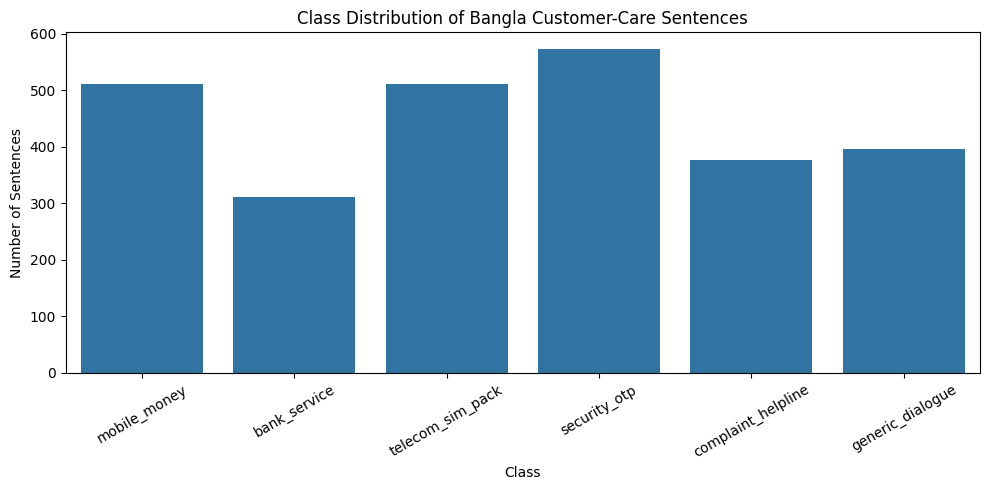

Total sentences: 2682
Largest class: security_otp
Largest class count: 574
Smallest class: bank_service
Smallest class count: 311
Class imbalance ratio: 1.85


In [ ]:

# ==========================================
# MEMBER 2: CLASS DISTRIBUTION
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

class_counts_m2 = (
    m2_data["label"]
    .value_counts()
    .reindex(EXPECTED_CLASSES, fill_value=0)
)

class_distribution_m2 = class_counts_m2.reset_index()
class_distribution_m2.columns = ["label", "count"]

display(class_distribution_m2)

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=class_distribution_m2,
    x="label",
    y="count"
)

plt.title("Class Distribution of Bangla Customer-Care Sentences")
plt.xlabel("Class")
plt.ylabel("Number of Sentences")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Imbalance analysis
imbalance_ratio = (
    class_counts_m2.max() / class_counts_m2.min()
)

print("Total sentences:", class_counts_m2.sum())
print("Largest class:", class_counts_m2.idxmax())
print("Largest class count:", class_counts_m2.max())
print("Smallest class:", class_counts_m2.idxmin())
print("Smallest class count:", class_counts_m2.min())
print("Class imbalance ratio:", round(imbalance_ratio, 2))


SENTENCE LENGTH STATISTICS
---------------------------
Total sentences: 2682
Minimum tokens: 3
Maximum tokens: 19
Average tokens: 11.1
Median tokens: 11.0
Standard deviation: 2.75


,sentence_id,sentence,raw_token_count
0,S0001,"দুঃখিত, আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড পা...",16
1,S0002,"ঠিক আছে, আপনি কি আগামীকাল সকাল এই সমস্যাটি প্র...",10
2,S0003,ডিপিএস কিস্তি পনেরো টাকা জমা হয়েছে।,6
3,S0004,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,12
4,S0005,আপনি কি ভুল করে ওটিপি অন্য কারও সাথে শেয়ার কর...,10
5,S0006,"বুঝতে পারছি, নতুন প্যাক চালুর আগে পুরোনো প্যাক...",11
6,S0007,"দুঃখিত, আপনার ডিবিবিএল ব্যাংক অনুরোধ গ্রহণ করা...",8
7,S0008,"জানানোর জন্য ধন্যবাদ, বিল পেমেন্ট সফল হলেও যদি...",17
8,S0009,"বুঝতে পারছি, আপনি কি ক্যাশ ইন করেছেন, নাকি অন্...",15
9,S0010,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,15


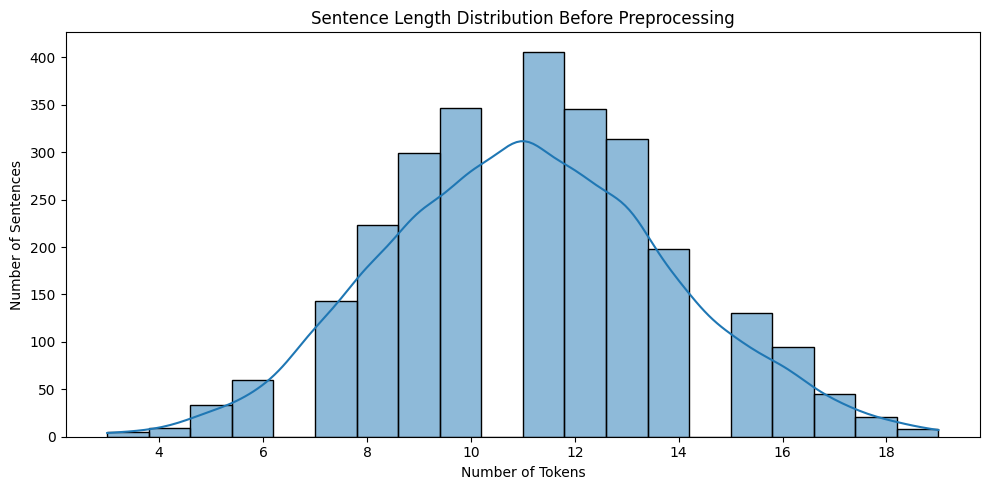

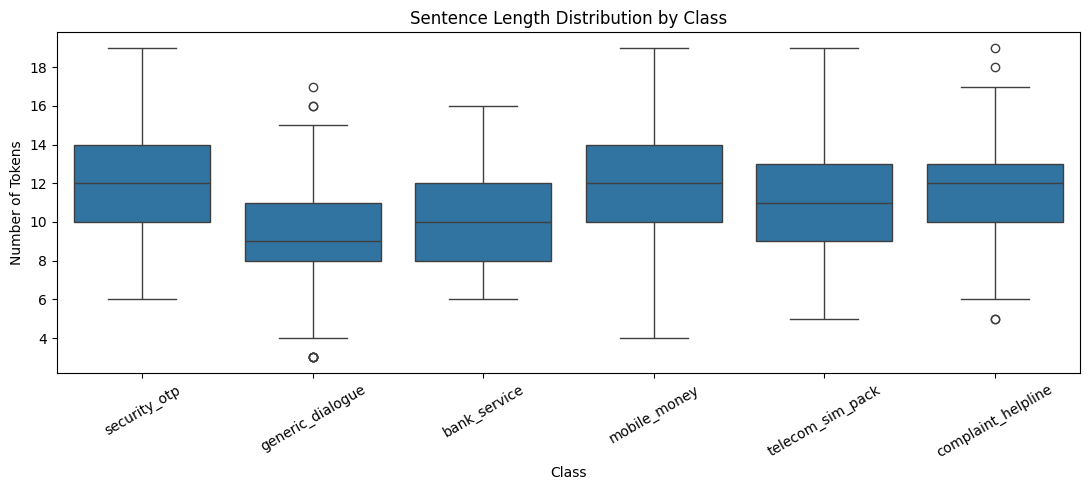

,mean,median,min,max
label,,,,
bank_service,10.09,10.0,6,16
complaint_helpline,11.65,12.0,5,19
generic_dialogue,9.26,9.0,3,17
mobile_money,11.72,12.0,4,19
security_otp,11.82,12.0,6,19
telecom_sim_pack,11.28,11.0,5,19


In [ ]:
# MEMBER 2: SENTENCE LENGTH ANALYSIS

import re
import matplotlib.pyplot as plt
import seaborn as sns

# Count words/tokens in each sentence
def count_raw_tokens(text):
    if pd.isna(text):
        return 0

    tokens = re.findall(
        r'[\u0980-\u09FF]+|[A-Za-z]+|[০-৯0-9]+',
        str(text)
    )
    return len(tokens)


# Calculate token count
m2_data["raw_token_count"] = m2_data["sentence"].apply(count_raw_tokens)


# Display statistics
print("SENTENCE LENGTH STATISTICS")
print("---------------------------")
print("Total sentences:", len(m2_data))
print("Minimum tokens:", m2_data["raw_token_count"].min())
print("Maximum tokens:", m2_data["raw_token_count"].max())
print("Average tokens:", round(m2_data["raw_token_count"].mean(), 2))
print("Median tokens:", m2_data["raw_token_count"].median())
print("Standard deviation:", round(m2_data["raw_token_count"].std(), 2))


# Display sample sentences
display(
    m2_data[["sentence_id", "sentence", "raw_token_count"]].head(10)
)


# Histogram
plt.figure(figsize=(10, 5))

sns.histplot(
    data=m2_data,
    x="raw_token_count",
    bins=20,
    kde=True
)

plt.title("Sentence Length Distribution Before Preprocessing")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Sentences")
plt.tight_layout()
plt.show()


# Sentence length by class
plt.figure(figsize=(11, 5))

sns.boxplot(
    data=m2_data,
    x="label",
    y="raw_token_count"
)

plt.title("Sentence Length Distribution by Class")
plt.xlabel("Class")
plt.ylabel("Number of Tokens")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Average sentence length for each class
length_by_class = (
    m2_data.groupby("label")["raw_token_count"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)

display(length_by_class)


Top 15 Frequent Words in mobile_money:


,Word,Frequency
0,কি,273
1,আপনার,268
2,ধন্যবাদ,144
3,টাকা,144
4,সময়,126
5,জন্য,121
6,আপনি,119
7,নম্বরটি,103
8,দেখাচ্ছে,102
9,রেফারেন্স,97



Top 15 Frequent Words in bank_service:


,Word,Frequency
0,আপনার,178
1,কি,150
2,কিস্তি,116
3,টাকা,116
4,ব্যাংক,111
5,ধন্যবাদ,90
6,হয়েছে,84
7,জন্য,84
8,ডিপিএস,64
9,চান,60



Top 15 Frequent Words in telecom_sim_pack:


,Word,Frequency
0,কি,394
1,আপনার,255
2,আপনি,232
3,রিচার্জ,196
4,প্যাক,173
5,ধন্যবাদ,141
6,এক,124
7,জন্য,121
8,কিনেছিলেন,116
9,টাকার,110


... (3 outputs left out)

,Word,Frequency
0,অভিযোগ,202
1,এক,193
2,তিন,189
3,শূন্য,184
4,সাত,177
5,দুই,167
6,নয়,165
7,আট,164
8,নম্বরটি,159
9,ছয়,155



Top 15 Frequent Words in generic_dialogue:


,Word,Frequency
0,কি,224
1,ধন্যবাদ,136
2,জন্য,126
3,আপনি,125
4,আপনার,123
5,আমি,99
6,আছে,80
7,এই,70
8,সমস্যাটি,55
9,সাথে,55


/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2453 (\N{BENGALI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2495 (\N{BENGALI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2438 (\N{BENGALI LETTER AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2474 (\N{BENGALI LETTER PA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2472 (\N{BENGALI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2494 (\N{BENGALI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426

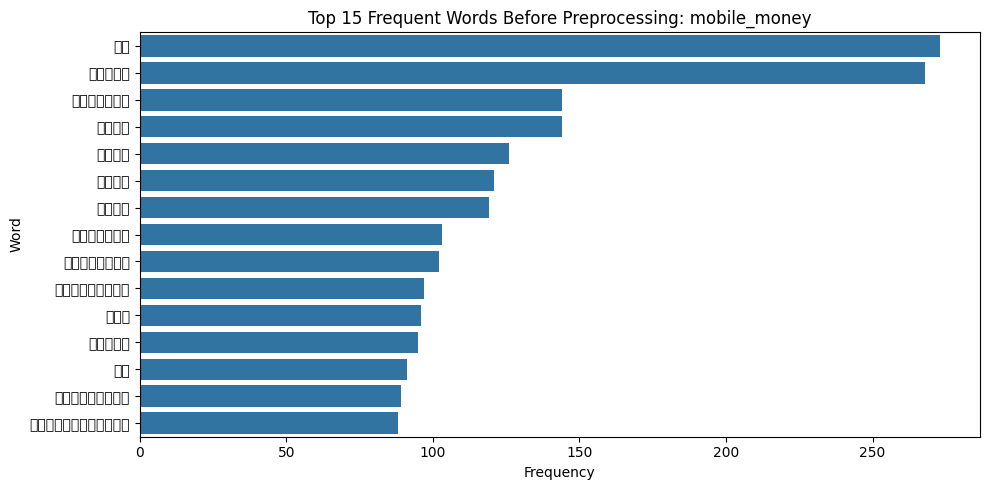

/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2438 (\N{BENGALI LETTER AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2474 (\N{BENGALI LETTER PA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2472 (\N{BENGALI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2494 (\N{BENGALI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2480 (\N{BENGALI LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2453 (\N{BENGALI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/19

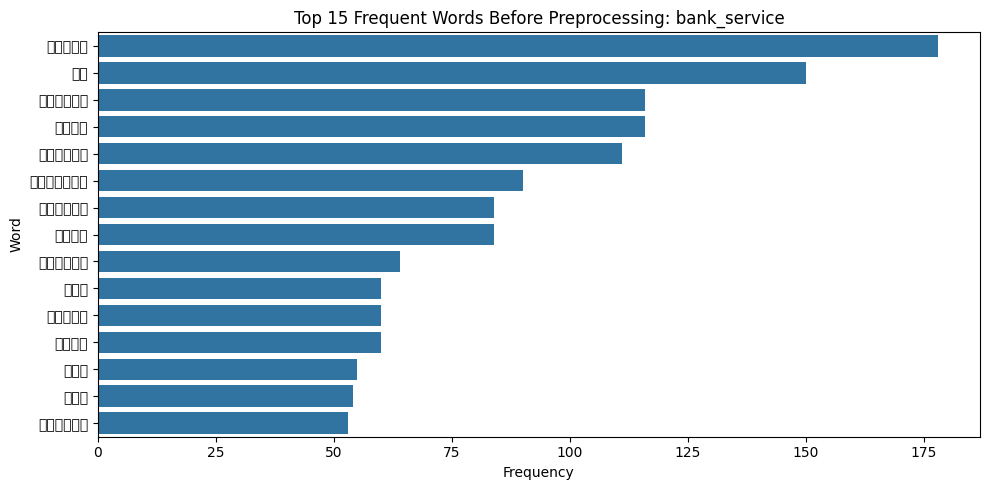

/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2453 (\N{BENGALI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2495 (\N{BENGALI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2438 (\N{BENGALI LETTER AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2474 (\N{BENGALI LETTER PA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2472 (\N{BENGALI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2494 (\N{BENGALI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426

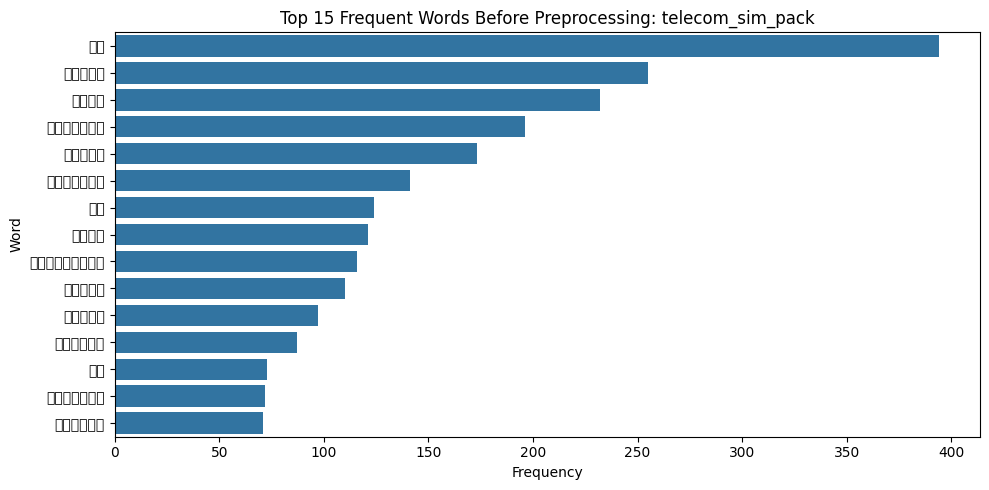

/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2438 (\N{BENGALI LETTER AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2474 (\N{BENGALI LETTER PA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2472 (\N{BENGALI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2494 (\N{BENGALI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2480 (\N{BENGALI LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2453 (\N{BENGALI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/19

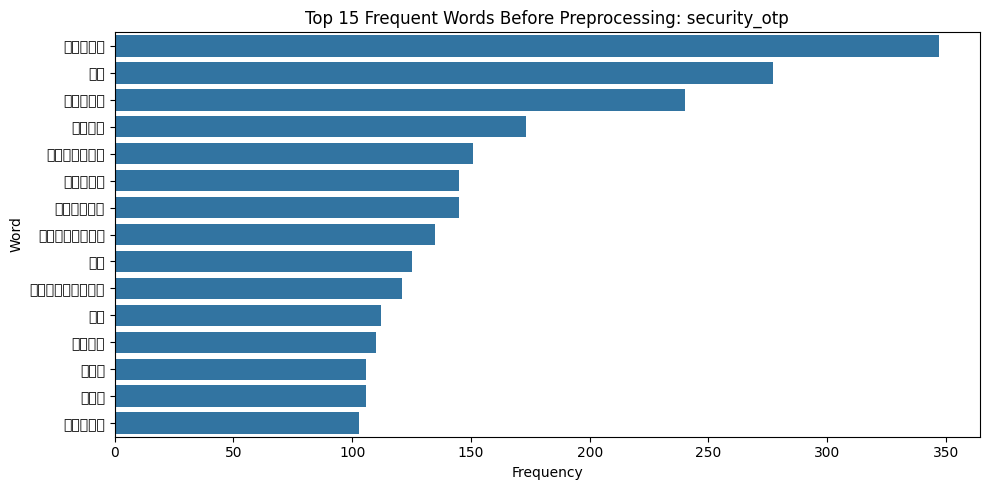

/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2437 (\N{BENGALI LETTER A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2477 (\N{BENGALI LETTER BHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2495 (\N{BENGALI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2479 (\N{BENGALI LETTER YA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2507 (\N{BENGALI VOWEL SIGN O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2455 (\N{BENGALI LETTER GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/

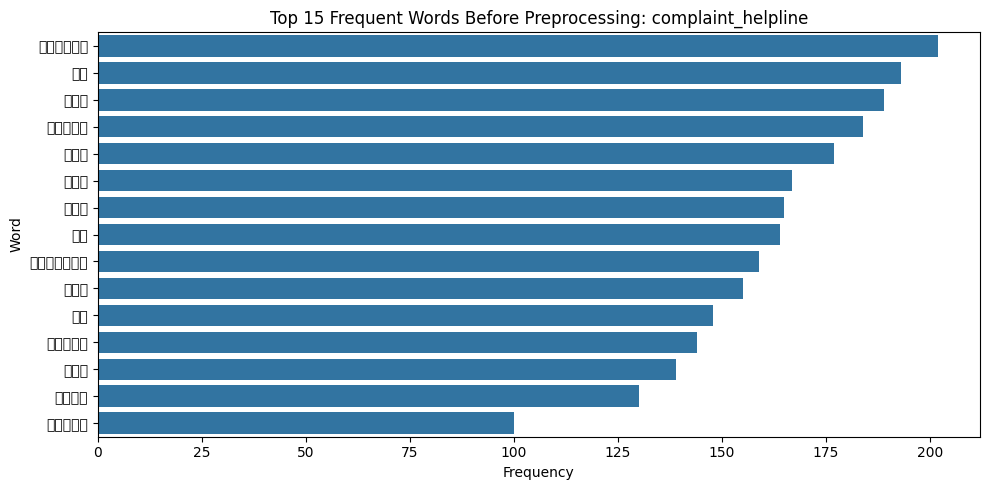

/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2453 (\N{BENGALI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2495 (\N{BENGALI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2471 (\N{BENGALI LETTER DHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2472 (\N{BENGALI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2509 (\N{BENGALI SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/1918617131.py:73: UserWarning: Glyph 2479 (\N{BENGALI LETTER YA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1426/

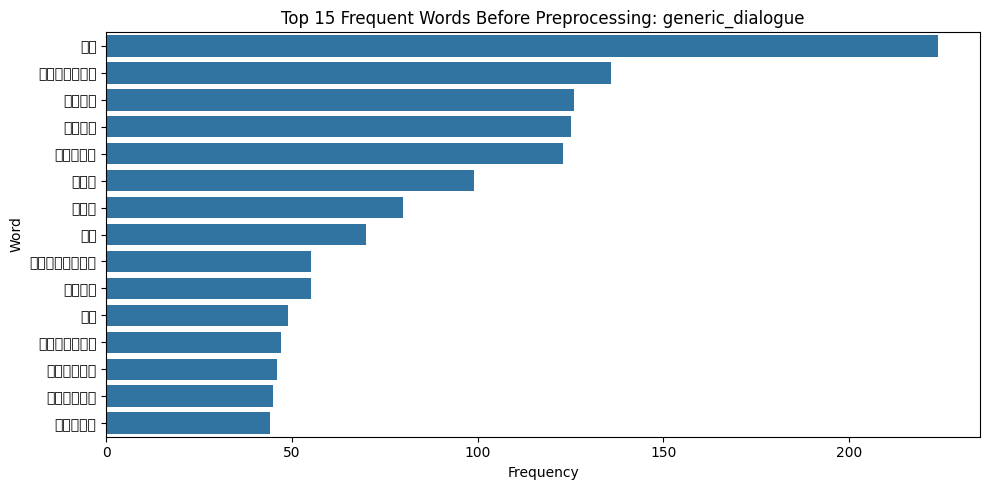

In [ ]:
# MEMBER 2: FREQUENT WORD ANALYSIS BEFORE PREPROCESSING

import re
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from collections import Counter

# Tokenize raw sentences
def raw_bangla_tokenize(text):
    if pd.isna(text):
        return []

    tokens = re.findall(
        r'[\u0980-\u09FF]+|[A-Za-z]+|[০-৯0-9]+',
        str(text).lower()
    )

    return tokens


# Store the top 15 frequent words for each class
top_words_before = {}

for label in EXPECTED_CLASSES:

    # Select sentences belonging to this class
    class_texts = m2_data.loc[
        m2_data["label"] == label, "sentence"
    ]

    all_tokens = []

    # Extract tokens from every sentence
    for sentence in class_texts:
        all_tokens.extend(raw_bangla_tokenize(sentence))

    # Count word frequencies
    word_counts = Counter(all_tokens)

    # Get top 15 words
    top_words_before[label] = word_counts.most_common(15)

    print(f"\nTop 15 Frequent Words in {label}:")

    words_df = pd.DataFrame(
        top_words_before[label],
        columns=["Word", "Frequency"]
    )

    display(words_df)


# Visualize frequent words for each class
for label in EXPECTED_CLASSES:

    words_df = pd.DataFrame(
        top_words_before[label],
        columns=["Word", "Frequency"]
    )

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=words_df,
        x="Frequency",
        y="Word"
    )

    plt.title(f"Top 15 Frequent Words Before Preprocessing: {label}")
    plt.xlabel("Frequency")
    plt.ylabel("Word")
    plt.tight_layout()
    plt.show()

In [ ]:
import re
import unicodedata
import pandas as pd
from collections import Counter

In [ ]:
def normalize_bangla(text):
    if pd.isna(text):
        return ""

    text = str(text)
    text = unicodedata.normalize("NFC", text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text

m2_data["normalized_sentence"] = (
    m2_data["sentence"].apply(normalize_bangla)
)

display(
    m2_data[["sentence", "normalized_sentence"]].head(10)
)

print("Total sentences:", len(m2_data))
print("Missing normalized sentences:",
      m2_data["normalized_sentence"].isna().sum())

,sentence,normalized_sentence
0,"দুঃখিত, আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড পা...","দুঃখিত, আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড পা..."
1,"ঠিক আছে, আপনি কি আগামীকাল সকাল এই সমস্যাটি প্র...","ঠিক আছে, আপনি কি আগামীকাল সকাল এই সমস্যাটি প্র..."
2,ডিপিএস কিস্তি পনেরো টাকা জমা হয়েছে।,ডিপিএস কিস্তি পনেরো টাকা জমা হয়েছে।
3,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...
4,আপনি কি ভুল করে ওটিপি অন্য কারও সাথে শেয়ার কর...,আপনি কি ভুল করে ওটিপি অন্য কারও সাথে শেয়ার কর...
5,"বুঝতে পারছি, নতুন প্যাক চালুর আগে পুরোনো প্যাক...","বুঝতে পারছি, নতুন প্যাক চালুর আগে পুরোনো প্যাক..."
6,"দুঃখিত, আপনার ডিবিবিএল ব্যাংক অনুরোধ গ্রহণ করা...","দুঃখিত, আপনার ডিবিবিএল ব্যাংক অনুরোধ গ্রহণ করা..."
7,"জানানোর জন্য ধন্যবাদ, বিল পেমেন্ট সফল হলেও যদি...","জানানোর জন্য ধন্যবাদ, বিল পেমেন্ট সফল হলেও যদি..."
8,"বুঝতে পারছি, আপনি কি ক্যাশ ইন করেছেন, নাকি অন্...","বুঝতে পারছি, আপনি কি ক্যাশ ইন করেছেন, নাকি অন্..."
9,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...


Total sentences: 2682
Missing normalized sentences: 0


In [ ]:
# BANGLA TOKENIZATION

def tokenize_bangla(text):
    if pd.isna(text):
        return []

    tokens = re.findall(
        r'[\u0980-\u09FF]+|[A-Za-z]+|[০-৯0-9]+',
        str(text)
    )

    return tokens


m2_data["tokens"] = (
    m2_data["normalized_sentence"].apply(tokenize_bangla)
)

print("Tokenization Results:")
display(
    m2_data[["normalized_sentence", "tokens"]].head(10)
)

Tokenization Results:


,normalized_sentence,tokens
0,"দুঃখিত, আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড পা...","[দুঃখিত, আপনার, নিরাপত্তা, যাচাইয়ের, নমুনা, ক..."
1,"ঠিক আছে, আপনি কি আগামীকাল সকাল এই সমস্যাটি প্র...","[ঠিক, আছে, আপনি, কি, আগামীকাল, সকাল, এই, সমস্য..."
2,ডিপিএস কিস্তি পনেরো টাকা জমা হয়েছে।,"[ডিপিএস, কিস্তি, পনেরো, টাকা, জমা, হয়েছে]"
3,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,"[আপনার, ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে..."
4,আপনি কি ভুল করে ওটিপি অন্য কারও সাথে শেয়ার কর...,"[আপনি, কি, ভুল, করে, ওটিপি, অন্য, কারও, সাথে, ..."
5,"বুঝতে পারছি, নতুন প্যাক চালুর আগে পুরোনো প্যাক...","[বুঝতে, পারছি, নতুন, প্যাক, চালুর, আগে, পুরোনো..."
6,"দুঃখিত, আপনার ডিবিবিএল ব্যাংক অনুরোধ গ্রহণ করা...","[দুঃখিত, আপনার, ডিবিবিএল, ব্যাংক, অনুরোধ, গ্রহ..."
7,"জানানোর জন্য ধন্যবাদ, বিল পেমেন্ট সফল হলেও যদি...","[জানানোর, জন্য, ধন্যবাদ, বিল, পেমেন্ট, সফল, হল..."
8,"বুঝতে পারছি, আপনি কি ক্যাশ ইন করেছেন, নাকি অন্...","[বুঝতে, পারছি, আপনি, কি, ক্যাশ, ইন, করেছেন, না..."
9,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,"[আপনার, ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে..."


In [ ]:
# EFINE BANGLA STOPWORDS

bangla_stopwords = {
    "আমি", "আমার", "আমাকে", "আমরা",
    "আপনি", "আপনার", "আপনাকে",
    "সে", "তার", "তাকে", "তারা",
    "এই", "এটি", "এটা", "ওই", "সেই",
    "এবং", "আর", "কিন্তু", "তবে",
    "যে", "যা", "যদি", "তাহলে",
    "কি", "কী", "কেন", "কিভাবে",
    "হয়", "হয়", "হচ্ছে", "হবে",
    "ছিল", "আছে", "নেই",
    "একটি", "একটা", "জন্য",
    "থেকে", "সাথে", "করে", "এর",
    "ও", "তো", "না", "হ্যাঁ"
}


# STEP 3: REMOVE STOPWORDS

def remove_stopwords(tokens):
    return [
        word for word in tokens
        if word not in bangla_stopwords
    ]


m2_data["tokens_without_stopwords"] = (
    m2_data["tokens"].apply(remove_stopwords)
)


print("Stopword Removal Results:")

display(
    m2_data[
        [
            "normalized_sentence",
            "tokens",
            "tokens_without_stopwords"
        ]
    ].head(10)
)

Stopword Removal Results:


,normalized_sentence,tokens,tokens_without_stopwords
0,"দুঃখিত, আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড পা...","[দুঃখিত, আপনার, নিরাপত্তা, যাচাইয়ের, নমুনা, ক...","[দুঃখিত, নিরাপত্তা, যাচাইয়ের, নমুনা, কোড, পাঁ..."
1,"ঠিক আছে, আপনি কি আগামীকাল সকাল এই সমস্যাটি প্র...","[ঠিক, আছে, আপনি, কি, আগামীকাল, সকাল, এই, সমস্য...","[ঠিক, আগামীকাল, সকাল, সমস্যাটি, প্রথম, দেখেছেন]"
2,ডিপিএস কিস্তি পনেরো টাকা জমা হয়েছে।,"[ডিপিএস, কিস্তি, পনেরো, টাকা, জমা, হয়েছে]","[ডিপিএস, কিস্তি, পনেরো, টাকা, জমা, হয়েছে]"
3,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,"[আপনার, ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে...","[ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে, রাখুন..."
4,আপনি কি ভুল করে ওটিপি অন্য কারও সাথে শেয়ার কর...,"[আপনি, কি, ভুল, করে, ওটিপি, অন্য, কারও, সাথে, ...","[ভুল, ওটিপি, অন্য, কারও, শেয়ার, করেছেন]"
5,"বুঝতে পারছি, নতুন প্যাক চালুর আগে পুরোনো প্যাক...","[বুঝতে, পারছি, নতুন, প্যাক, চালুর, আগে, পুরোনো...","[বুঝতে, পারছি, নতুন, প্যাক, চালুর, আগে, পুরোনো..."
6,"দুঃখিত, আপনার ডিবিবিএল ব্যাংক অনুরোধ গ্রহণ করা...","[দুঃখিত, আপনার, ডিবিবিএল, ব্যাংক, অনুরোধ, গ্রহ...","[দুঃখিত, ডিবিবিএল, ব্যাংক, অনুরোধ, গ্রহণ, করা,..."
7,"জানানোর জন্য ধন্যবাদ, বিল পেমেন্ট সফল হলেও যদি...","[জানানোর, জন্য, ধন্যবাদ, বিল, পেমেন্ট, সফল, হল...","[জানানোর, ধন্যবাদ, বিল, পেমেন্ট, সফল, হলেও, রস..."
8,"বুঝতে পারছি, আপনি কি ক্যাশ ইন করেছেন, নাকি অন্...","[বুঝতে, পারছি, আপনি, কি, ক্যাশ, ইন, করেছেন, না...","[বুঝতে, পারছি, ক্যাশ, ইন, করেছেন, নাকি, অন্য, ..."
9,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,"[আপনার, ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে...","[ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে, রাখুন..."


In [ ]:
print("Total sentences:", len(m2_data))

print(
    "Total tokens before stopword removal:",
    m2_data["tokens"].apply(len).sum()
)

print(
    "Total tokens after stopword removal:",
    m2_data["tokens_without_stopwords"].apply(len).sum()
)

print(
    "Total stopwords removed:",
    m2_data["tokens"].apply(len).sum()
    - m2_data["tokens_without_stopwords"].apply(len).sum()
)

Total sentences: 2682
Total tokens before stopword removal: 29759
Total tokens after stopword removal: 23803
Total stopwords removed: 5956


In [ ]:
# FINAL CONSERVATIVE BANGLA STEMMER

bangla_suffixes = [
    "গুলোর", "গুলোকে", "গুলিতে",
    "গুলো", "গুলি",
    "দেরকে",
    "টির", "টিকে",
    "তে", "কে"
]


def light_stem(word):

    for suffix in sorted(bangla_suffixes, key=len, reverse=True):

        if word.endswith(suffix):

            root = word[:-len(suffix)]

            if len(root) >= 3:
                return root

    return word


# Apply updated stemming
m2_data["stemmed_tokens"] = (
    m2_data["tokens_without_stopwords"].apply(
        lambda tokens: [light_stem(word) for word in tokens]
    )
)

In [ ]:
# Count total tokens before and after stemming

before_stemming = sum(
    len(tokens)
    for tokens in m2_data["tokens_without_stopwords"]
)

after_stemming = sum(
    len(tokens)
    for tokens in m2_data["stemmed_tokens"]
)

changed_tokens = sum(
    1
    for before, after in zip(
        m2_data["tokens_without_stopwords"],
        m2_data["stemmed_tokens"]
    )
    for before_word, after_word in zip(before, after)
    if before_word != after_word
)

print("Total tokens before stemming:", before_stemming)
print("Total tokens after stemming:", after_stemming)
print("Number of tokens changed:", changed_tokens)

Total tokens before stemming: 23803
Total tokens after stemming: 23803
Number of tokens changed: 498


In [ ]:
test_words = [
    "চার", "শেয়ার", "নম্বর", "আমাদের",
    "বুঝতে", "লাগতে", "জানতে",
    "টিমকে", "চালুর", "অসুবিধার"
]

for word in test_words:
    print(word, "->", light_stem(word))

চার -> চার
শেয়ার -> শেয়ার
নম্বর -> নম্বর
আমাদের -> আমাদের
বুঝতে -> বুঝ
লাগতে -> লাগ
জানতে -> জান
টিমকে -> টিম
চালুর -> চালুর
অসুবিধার -> অসুবিধার


In [ ]:
def remove_stopwords_function(tokens):
    return [
        word for word in tokens
        if word not in bangla_stopwords
    ]

In [ ]:
# REUSABLE PREPROCESSING FUNCTION

def preprocess_text(text, remove_stopwords=False, stemming=False):

    # 1. Unicode normalization
    text = normalize_bangla(text)

    # 2. Tokenization
    tokens = tokenize_bangla(text)

    # 3. Stopword removal
    if remove_stopwords:
        tokens = remove_stopwords_function(tokens)

    # 4. Light stemming
    if stemming:
        tokens = [light_stem(word) for word in tokens]

    return tokens

In [ ]:
sample = "আপনার বিকাশ একাউন্টে সমস্যা হচ্ছে"

print("Configuration A:", preprocess_text(sample, False, False))
print("Configuration B:", preprocess_text(sample, True, False))
print("Configuration C:", preprocess_text(sample, False, True))
print("Configuration D:", preprocess_text(sample, True, True))

Configuration A: ['আপনার', 'বিকাশ', 'একাউন্টে', 'সমস্যা', 'হচ্ছে']
Configuration B: ['বিকাশ', 'একাউন্টে', 'সমস্যা']
Configuration C: ['আপনার', 'বিকাশ', 'একাউন্টে', 'সমস্যা', 'হচ্ছে']
Configuration D: ['বিকাশ', 'একাউন্টে', 'সমস্যা']


In [ ]:
# Generate four preprocessing configurations

m2_data["config_A"] = m2_data["sentence"].apply(
    lambda x: preprocess_text(x, False, False)
)

m2_data["config_B"] = m2_data["sentence"].apply(
    lambda x: preprocess_text(x, True, False)
)

m2_data["config_C"] = m2_data["sentence"].apply(
    lambda x: preprocess_text(x, False, True)
)

m2_data["config_D"] = m2_data["sentence"].apply(
    lambda x: preprocess_text(x, True, True)
)

print("All four configurations generated successfully!")

display(
    m2_data[
        ["sentence", "config_A", "config_B", "config_C", "config_D"]
    ].head(10)
)

All four configurations generated successfully!


,sentence,config_A,config_B,config_C,config_D
0,"দুঃখিত, আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড পা...","[দুঃখিত, আপনার, নিরাপত্তা, যাচাইয়ের, নমুনা, ক...","[দুঃখিত, নিরাপত্তা, যাচাইয়ের, নমুনা, কোড, পাঁ...","[দুঃখিত, আপনার, নিরাপত্তা, যাচাইয়ের, নমুনা, ক...","[দুঃখিত, নিরাপত্তা, যাচাইয়ের, নমুনা, কোড, পাঁ..."
1,"ঠিক আছে, আপনি কি আগামীকাল সকাল এই সমস্যাটি প্র...","[ঠিক, আছে, আপনি, কি, আগামীকাল, সকাল, এই, সমস্য...","[ঠিক, আগামীকাল, সকাল, সমস্যাটি, প্রথম, দেখেছেন]","[ঠিক, আছে, আপনি, কি, আগামীকাল, সকাল, এই, সমস্য...","[ঠিক, আগামীকাল, সকাল, সমস্যাটি, প্রথম, দেখেছেন]"
2,ডিপিএস কিস্তি পনেরো টাকা জমা হয়েছে।,"[ডিপিএস, কিস্তি, পনেরো, টাকা, জমা, হয়েছে]","[ডিপিএস, কিস্তি, পনেরো, টাকা, জমা, হয়েছে]","[ডিপিএস, কিস্তি, পনেরো, টাকা, জমা, হয়েছে]","[ডিপিএস, কিস্তি, পনেরো, টাকা, জমা, হয়েছে]"
3,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,"[আপনার, ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে...","[ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে, রাখুন...","[আপনার, ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে...","[ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে, রাখুন..."
4,আপনি কি ভুল করে ওটিপি অন্য কারও সাথে শেয়ার কর...,"[আপনি, কি, ভুল, করে, ওটিপি, অন্য, কারও, সাথে, ...","[ভুল, ওটিপি, অন্য, কারও, শেয়ার, করেছেন]","[আপনি, কি, ভুল, করে, ওটিপি, অন্য, কারও, সাথে, ...","[ভুল, ওটিপি, অন্য, কারও, শেয়ার, করেছেন]"
5,"বুঝতে পারছি, নতুন প্যাক চালুর আগে পুরোনো প্যাক...","[বুঝতে, পারছি, নতুন, প্যাক, চালুর, আগে, পুরোনো...","[বুঝতে, পারছি, নতুন, প্যাক, চালুর, আগে, পুরোনো...","[বুঝ, পারছি, নতুন, প্যাক, চালুর, আগে, পুরোনো, ...","[বুঝ, পারছি, নতুন, প্যাক, চালুর, আগে, পুরোনো, ..."
6,"দুঃখিত, আপনার ডিবিবিএল ব্যাংক অনুরোধ গ্রহণ করা...","[দুঃখিত, আপনার, ডিবিবিএল, ব্যাংক, অনুরোধ, গ্রহ...","[দুঃখিত, ডিবিবিএল, ব্যাংক, অনুরোধ, গ্রহণ, করা,...","[দুঃখিত, আপনার, ডিবিবিএল, ব্যাংক, অনুরোধ, গ্রহ...","[দুঃখিত, ডিবিবিএল, ব্যাংক, অনুরোধ, গ্রহণ, করা,..."
7,"জানানোর জন্য ধন্যবাদ, বিল পেমেন্ট সফল হলেও যদি...","[জানানোর, জন্য, ধন্যবাদ, বিল, পেমেন্ট, সফল, হল...","[জানানোর, ধন্যবাদ, বিল, পেমেন্ট, সফল, হলেও, রস...","[জানানোর, জন্য, ধন্যবাদ, বিল, পেমেন্ট, সফল, হল...","[জানানোর, ধন্যবাদ, বিল, পেমেন্ট, সফল, হলেও, রস..."
8,"বুঝতে পারছি, আপনি কি ক্যাশ ইন করেছেন, নাকি অন্...","[বুঝতে, পারছি, আপনি, কি, ক্যাশ, ইন, করেছেন, না...","[বুঝতে, পারছি, ক্যাশ, ইন, করেছেন, নাকি, অন্য, ...","[বুঝ, পারছি, আপনি, কি, ক্যাশ, ইন, করেছেন, নাকি...","[বুঝ, পারছি, ক্যাশ, ইন, করেছেন, নাকি, অন্য, কে..."
9,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,"[আপনার, ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে...","[ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে, রাখুন...","[আপনার, ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে...","[ট্রানজ্যাকশন, রেফারেন্স, নম্বরটি, শুনে, রাখুন..."


In [ ]:
config_columns = [
    "config_A", "config_B", "config_C", "config_D"
]

for config in config_columns:
    total = m2_data[config].apply(len).sum()
    print(config, "Total tokens:", total)

config_A Total tokens: 29759
config_B Total tokens: 23803
config_C Total tokens: 29759
config_D Total tokens: 23803


In [ ]:
print("Master dataset columns:")
print(master.columns.tolist())

print("\nUnique document IDs:", master["doc_id"].nunique())

print("\nSample document IDs:")
display(master[["sentence_id", "doc_id"]].head(15))

Master dataset columns:
['sentence_id', 'sentence', 'doc_id', 'owner']

Unique document IDs: 2605

Sample document IDs:


,sentence_id,doc_id
0,S0001,1531
1,S0002,3984
2,S0003,3337
3,S0004,9516
4,S0005,158
5,S0006,117
6,S0007,3916
7,S0008,455
8,S0009,8721
9,S0010,7826


In [ ]:
import os

print("Available CSV files:")

for file in os.listdir("/content"):
    if file.endswith(".csv"):
        print(file)

Available CSV files:
M2_independent.csv
M3_independent.csv
master_sentences.csv
gold_labels_final.csv
final_adjudication_decisions.csv
M1_independent.csv
template_candidate_pairs.csv


In [ ]:
# STEP 1: PREPARE SENTENCES FOR TEMPLATE COMPARISON

import re
import unicodedata
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def prepare_for_grouping(text):

    text = unicodedata.normalize("NFC", str(text))

    # Replace numbers with a common placeholder
    text = re.sub(r'[০-৯0-9]+', ' NUM ', text)

    # Remove punctuation and normalize whitespace
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text


m2_data["grouping_text"] = (
    m2_data["sentence"].apply(prepare_for_grouping)
)

print("Sentences prepared:", len(m2_data))

Sentences prepared: 2682


In [ ]:
# STEP 2: CHARACTER-LEVEL TF-IDF

vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=1
)

X = vectorizer.fit_transform(m2_data["grouping_text"])

# Calculate pairwise cosine similarity
similarity_matrix = cosine_similarity(X)

print("Similarity matrix shape:", similarity_matrix.shape)

Similarity matrix shape: (2682, 2682)


In [ ]:
# STEP 3: FIND POTENTIALLY SIMILAR SENTENCES
threshold = 0.80

row_indices, col_indices = np.where(
    np.triu(similarity_matrix, k=1) >= threshold
)

candidate_pairs = []

for i, j in zip(row_indices, col_indices):

    candidate_pairs.append({
        "sentence_id_1": m2_data.iloc[i]["sentence_id"],
        "sentence_1": m2_data.iloc[i]["sentence"],
        "doc_id_1": m2_data.iloc[i]["doc_id"],

        "sentence_id_2": m2_data.iloc[j]["sentence_id"],
        "sentence_2": m2_data.iloc[j]["sentence"],
        "doc_id_2": m2_data.iloc[j]["doc_id"],

        "similarity_score": round(
            similarity_matrix[i, j], 4
        ),

        "review_decision": "",
        "reviewer_note": ""
    })

candidate_df = pd.DataFrame(candidate_pairs)

candidate_df = candidate_df.sort_values(
    "similarity_score",
    ascending=False
).reset_index(drop=True)

print("Candidate pairs found:", len(candidate_df))

display(candidate_df.head(20))

Candidate pairs found: 21281


,sentence_id_1,sentence_1,doc_id_1,sentence_id_2,sentence_2,doc_id_2,similarity_score,review_decision,reviewer_note
0,S0657,আপনার নিবন্ধিত মোবাইল নম্বরের শেষ কয়েকটি অঙ্ক...,3012,S0914,আপনার নিবন্ধিত মোবাইল নম্বরের শেষ কয়েকটি অঙ্ক...,1495,1.0000,,
1,S0329,ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে এক সাত ছয় দুই...,7131,S2262,ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে এক ছয় দুই সাত...,6761,1.0000,,
2,S2001,জানানোর জন্য ধন্যবাদ!,3210,S2601,জানানোর জন্য ধন্যবাদ।,370,1.0000,,
3,S0097,ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে ছয় দুই ছয় সা...,4536,S1704,ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে ছয় তিন ছয় দু...,4044,0.9967,,
4,S0883,"জানানোর জন্য ধন্যবাদ, ওটিপি ইনপুট ফিল্ডে নমুনা...",6985,S2641,"জানানোর জন্য ধন্যবাদ, ওটিপি ইনপুট ফিল্ডে নমুনা...",769,0.9967,,
5,S0362,"দুঃখিত, এটিএম বুথের অবস্থান বললে আমরা নিকটস্থ ...",2985,S0812,এটিএম বুথের অবস্থান বললে আমরা নিকটস্থ সাপোর্ট ...,251,0.9964,,
6,S0212,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,4907,S1345,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,6099,0.9964,,
7,S0526,ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে দুই সাত আট সাত...,1604,S2211,ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে দুই সাত তিন আট...,8940,0.9962,,
8,S0343,ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে সাত শূন্য পাঁচ...,5134,S0807,ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে দুই তিন পাঁচ শ...,4351,0.9960,,
9,S0833,ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে পাঁচ দুই পাঁচ ...,7050,S1075,ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে পাঁচ চার দুই স...,2560,0.9959,,


In [90]:
# STEP 4: SAVE CANDIDATE PAIRS

candidate_df.to_csv(
    "/content/template_candidate_pairs.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved: /content/template_candidate_pairs.csv")

Saved: /content/template_candidate_pairs.csv


In [ ]:
print(candidate_df.shape)
print(candidate_df.columns.tolist())

candidate_df.to_csv(
    "/content/template_candidate_pairs.csv",
    index=False,
    encoding="utf-8-sig"
)

(21281, 9)
['sentence_id_1', 'sentence_1', 'doc_id_1', 'sentence_id_2', 'sentence_2', 'doc_id_2', 'similarity_score', 'review_decision', 'reviewer_note']


In [92]:
import re
import unicodedata

bangla_number_words = [
    "শূন্য", "এক", "দুই", "তিন", "চার",
    "পাঁচ", "ছয়", "ছয়", "সাত", "আট",
    "নয়", "নয়", "দশ", "এগারো", "বারো",
    "তেরো", "চৌদ্দ", "পনেরো", "ষোলো",
    "সতেরো", "আঠারো", "উনিশ", "বিশ"
]

def prepare_template_text(text):

    # Unicode normalization
    text = unicodedata.normalize("NFC", str(text))

    # Replace numerical digits
    text = re.sub(r'[০-৯0-9]+', ' NUM ', text)

    # Preserve Bangla characters and signs while removing punctuation
    text = re.sub(
        r'[^\u0980-\u09FFA-Za-z0-9\s]',
        ' ',
        text
    )

    # Replace standalone Bangla number words
    for word in bangla_number_words:
        text = re.sub(
            rf'(?<![\u0980-\u09FF]){word}(?![\u0980-\u09FF])',
            ' NUM ',
            text
        )

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


m2_data["grouping_text"] = (
    m2_data["sentence"].apply(prepare_template_text)
)

display(m2_data[["sentence", "grouping_text"]].head(10))

,sentence,grouping_text
0,"দুঃখিত, আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড পা...",দুঃখিত আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড NUM...
1,"ঠিক আছে, আপনি কি আগামীকাল সকাল এই সমস্যাটি প্র...",ঠিক আছে আপনি কি আগামীকাল সকাল এই সমস্যাটি প্রথ...
2,ডিপিএস কিস্তি পনেরো টাকা জমা হয়েছে।,ডিপিএস কিস্তি NUM টাকা জমা হয়েছে
3,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...
4,আপনি কি ভুল করে ওটিপি অন্য কারও সাথে শেয়ার কর...,আপনি কি ভুল করে ওটিপি অন্য কারও সাথে শেয়ার কর...
5,"বুঝতে পারছি, নতুন প্যাক চালুর আগে পুরোনো প্যাক...",বুঝতে পারছি নতুন প্যাক চালুর আগে পুরোনো প্যাকে...
6,"দুঃখিত, আপনার ডিবিবিএল ব্যাংক অনুরোধ গ্রহণ করা...",দুঃখিত আপনার ডিবিবিএল ব্যাংক অনুরোধ গ্রহণ করা ...
7,"জানানোর জন্য ধন্যবাদ, বিল পেমেন্ট সফল হলেও যদি...",জানানোর জন্য ধন্যবাদ বিল পেমেন্ট সফল হলেও যদি ...
8,"বুঝতে পারছি, আপনি কি ক্যাশ ইন করেছেন, নাকি অন্...",বুঝতে পারছি আপনি কি ক্যাশ ইন করেছেন নাকি অন্য ...
9,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...


In [93]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

# Step 1: Convert normalized sentences into character n-gram TF-IDF
vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=1
)

X = vectorizer.fit_transform(m2_data["grouping_text"])

# Step 2: Calculate pairwise similarity
similarity_matrix = cosine_similarity(X)

print("Similarity matrix:", similarity_matrix.shape)

# Step 3: Find candidate pairs with similarity >= 0.80
threshold = 0.80

row_indices, col_indices = np.where(
    np.triu(similarity_matrix, k=1) >= threshold
)

candidate_pairs = []

for i, j in zip(row_indices, col_indices):
    candidate_pairs.append({
        "sentence_id_1": m2_data.iloc[i]["sentence_id"],
        "sentence_1": m2_data.iloc[i]["sentence"],
        "doc_id_1": m2_data.iloc[i]["doc_id"],
        "sentence_id_2": m2_data.iloc[j]["sentence_id"],
        "sentence_2": m2_data.iloc[j]["sentence"],
        "doc_id_2": m2_data.iloc[j]["doc_id"],
        "similarity_score": round(float(similarity_matrix[i, j]), 4),
        "review_decision": "",
        "reviewer_note": ""
    })

candidate_df = pd.DataFrame(candidate_pairs)

if not candidate_df.empty:
    candidate_df = candidate_df.sort_values(
        "similarity_score",
        ascending=False
    ).reset_index(drop=True)

print("Candidate pairs found:", len(candidate_df))

display(candidate_df.head(20))

Similarity matrix: (2682, 2682)
Candidate pairs found: 33412


,sentence_id_1,sentence_1,doc_id_1,sentence_id_2,sentence_2,doc_id_2,similarity_score,review_decision,reviewer_note
0,S2586,"হেল্পলাইন নম্বরটি শুনে নিন, শূন্য এক নয় আট সা...",7517,S2663,"হেল্পলাইন নম্বরটি শুনে নিন, শূন্য এক নয় দুই স...",7429,1.0,,
1,S0670,আপনার অভিযোগ নম্বরটি কি তিন সাত নয় পাঁচ আট তি...,532,S1399,আপনার অভিযোগ নম্বরটি কি চার আট তিন এক আট সাত দ...,9105,1.0,,
2,S2619,"হেল্পলাইন নম্বরটি শুনে নিন, দুই তিন তিন এক নয়...",3665,S2678,"হেল্পলাইন নম্বরটি শুনে নিন, শূন্য এক নয় ছয় ত...",3910,1.0,,
3,S0670,আপনার অভিযোগ নম্বরটি কি তিন সাত নয় পাঁচ আট তি...,532,S1022,আপনার অভিযোগ নম্বরটি কি সাত দুই পাঁচ ছয় শূন্য...,7829,1.0,,
4,S0212,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,4907,S1086,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,2488,1.0,,
5,S0212,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,4907,S0973,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,74,1.0,,
6,S0212,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,4907,S0867,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,6211,1.0,,
7,S0835,আপনার অভিযোগ নম্বরটি কি এক সাত ছয় তিন শূন্য এ...,1943,S1909,আপনার অভিযোগ নম্বরটি কি তিন শূন্য শূন্য আট নয়...,1799,1.0,,
8,S0212,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,4907,S0255,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,512,1.0,,
9,S1515,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,5254,S1835,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,1273,1.0,,


In [94]:
# Collapse consecutive NUM placeholders into one NUM
m2_data["template_text"] = m2_data["grouping_text"].apply(
    lambda text: re.sub(r'(?:\bNUM\b\s*)+', 'NUM ', text).strip()
)

# Find sentences with exactly matching normalized template text
exact_template_groups = (
    m2_data.groupby("template_text")
    .agg(
        sentence_count=("sentence_id", "count"),
        sentence_ids=("sentence_id", list),
        original_sentences=("sentence", list)
    )
    .reset_index()
)

# Keep groups containing at least two sentences
exact_template_groups = exact_template_groups[
    exact_template_groups["sentence_count"] >= 2
].sort_values("sentence_count", ascending=False)

print("Exact matching template groups:",
      len(exact_template_groups))

print("Sentences in these groups:",
      exact_template_groups["sentence_count"].sum())

display(
    exact_template_groups[
        ["template_text", "sentence_count", "original_sentences"]
    ].head(20)
)

Exact matching template groups: 89
Sentences in these groups: 714


,template_text,sentence_count,original_sentences
58,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,65,[আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখ...
27,আপনার অভিযোগ নম্বরটি কি NUM দিয়ে শুরু,55,[আপনার অভিযোগ নম্বরটি কি আট সাত সাত ছয় চার সা...
12,অভিযোগ নম্বর NUM সংরক্ষণ করুন,54,[অভিযোগ নম্বর চার শূন্য আট শূন্য দুই সংরক্ষণ ক...
288,আপনার নিবন্ধিত মোবাইল নম্বরের শেষ কয়েকটি অঙ্ক...,53,[আপনার নিবন্ধিত মোবাইল নম্বরের শেষ কয়েকটি অঙ্...
2030,রিচার্জ নম্বরটি কি NUM হিসেবে দিয়েছিলেন,51,[রিচার্জ নম্বরটি কি শূন্য এক আট তিন নয় সাত শূ...
644,ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে NUM ফরম্যাটে স...,49,[ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে ছয় দুই ছয় স...
2056,হেল্পলাইন নম্বরটি শুনে নিন NUM,48,"[হেল্পলাইন নম্বরটি শুনে নিন, শূন্য এক সাত তিন ..."
289,আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড NUM এটি শু...,46,[আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড পাঁচ সাত ...
668,চিন্তা করবেন না অভিযোগ নম্বর NUM সংরক্ষণ করুন,9,"[চিন্তা করবেন না, অভিযোগ নম্বর শূন্য আট সাত দু..."
905,জানানোর জন্য ধন্যবাদ আপনার ট্রানজ্যাকশন রেফারে...,8,"[জানানোর জন্য ধন্যবাদ, আপনার ট্রানজ্যাকশন রেফা..."


In [95]:
# Step 1: Select the 89 duplicate template groups
review_templates = (
    exact_template_groups
    .sort_values("sentence_count", ascending=False)
    .reset_index(drop=True)
)

# Step 2: Assign temporary candidate group IDs
review_templates["candidate_group_id"] = [
    f"TG{i+1:03d}" for i in range(len(review_templates))
]

template_to_group = dict(zip(
    review_templates["template_text"],
    review_templates["candidate_group_id"]
))

# Step 3: Get all sentences belonging to these groups
group_members = m2_data[
    m2_data["template_text"].isin(template_to_group)
].copy()

group_members["candidate_group_id"] = (
    group_members["template_text"].map(template_to_group)
)

# Step 4: Create one summary row per group
review_summary = (
    group_members.groupby("candidate_group_id")
    .agg(
        template_text=("template_text", "first"),
        sentence_count=("sentence_id", "size"),
        unique_doc_count=("doc_id", "nunique"),
        labels=("label", lambda x: ", ".join(sorted(set(x.dropna())))),
        examples=("sentence", lambda x: " || ".join(x.head(5)))
    )
    .reset_index()
)

# Add review columns
review_summary["review_decision"] = ""
review_summary["reviewer_note"] = ""

# Step 5: Create a detailed sentence-to-group mapping
review_members = group_members[
    ["candidate_group_id", "sentence_id",
     "sentence", "doc_id", "label"]
].copy()

# Step 6: Export both files
review_summary.to_csv(
    "/content/template_group_review.csv",
    index=False,
    encoding="utf-8-sig"
)

review_members.to_csv(
    "/content/template_group_members.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Review groups:", len(review_summary))
print("Sentences in candidate groups:", len(review_members))

print("\nFirst 15 groups:")
display(review_summary.head(15))

print("\nExport completed!")

Review groups: 89
Sentences in candidate groups: 714

First 15 groups:


,candidate_group_id,template_text,sentence_count,unique_doc_count,labels,examples,review_decision,reviewer_note
0,TG001,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,65,65,mobile_money,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,,
1,TG002,আপনার অভিযোগ নম্বরটি কি NUM দিয়ে শুরু,55,55,complaint_helpline,আপনার অভিযোগ নম্বরটি কি আট সাত সাত ছয় চার সাত...,,
2,TG003,অভিযোগ নম্বর NUM সংরক্ষণ করুন,54,54,complaint_helpline,অভিযোগ নম্বর চার শূন্য আট শূন্য দুই সংরক্ষণ কর...,,
3,TG004,আপনার নিবন্ধিত মোবাইল নম্বরের শেষ কয়েকটি অঙ্ক...,53,53,security_otp,আপনার নিবন্ধিত মোবাইল নম্বরের শেষ কয়েকটি অঙ্ক...,,
4,TG005,রিচার্জ নম্বরটি কি NUM হিসেবে দিয়েছিলেন,51,51,telecom_sim_pack,রিচার্জ নম্বরটি কি শূন্য এক আট তিন নয় সাত শূন...,,
5,TG006,ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে NUM ফরম্যাটে স...,49,49,security_otp,ওটিপি ইনপুট ফিল্ডে নমুনা হিসেবে ছয় দুই ছয় সা...,,
6,TG007,হেল্পলাইন নম্বরটি শুনে নিন NUM,48,48,complaint_helpline,"হেল্পলাইন নম্বরটি শুনে নিন, শূন্য এক সাত তিন ছ...",,
7,TG008,আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড NUM এটি শু...,46,46,security_otp,আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড পাঁচ সাত এ...,,
8,TG009,চিন্তা করবেন না অভিযোগ নম্বর NUM সংরক্ষণ করুন,9,9,complaint_helpline,"চিন্তা করবেন না, অভিযোগ নম্বর শূন্য আট সাত দুই...",,
9,TG010,জানানোর জন্য ধন্যবাদ আপনার ট্রানজ্যাকশন রেফারে...,8,8,mobile_money,"জানানোর জন্য ধন্যবাদ, আপনার ট্রানজ্যাকশন রেফার...",,



Export completed!


In [96]:
from collections import defaultdict
import pandas as pd

# 1. Create a parent entry for every sentence
parent = {
    sid: sid for sid in m2_data["sentence_id"]
}

# 2. Find the root of a sentence group
def find(x):
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

# 3. Combine two sentence groups
def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a

# 4. Group sentences from the same original document
for doc_id, group in m2_data.dropna(subset=["doc_id"]).groupby("doc_id"):
    sentence_ids = group["sentence_id"].tolist()

    for sid in sentence_ids[1:]:
        union(sentence_ids[0], sid)

# 5. Group sentences from the same provisional template
for group_id, group in group_members.groupby("candidate_group_id"):
    sentence_ids = group["sentence_id"].tolist()

    for sid in sentence_ids[1:]:
        union(sentence_ids[0], sid)

# 6. Assign a final connected-component group ID
m2_data["final_group_root"] = (
    m2_data["sentence_id"].apply(find)
)

root_to_group = {
    root: f"FG{i+1:04d}"
    for i, root in enumerate(
        sorted(m2_data["final_group_root"].unique())
    )
}

m2_data["final_group_id"] = (
    m2_data["final_group_root"].map(root_to_group)
)

# 7. Generate group statistics
final_group_summary = (
    m2_data.groupby("final_group_id")
    .agg(
        sentence_count=("sentence_id", "count"),
        unique_documents=("doc_id", "nunique"),
        label_count=("label", "nunique"),
        labels=("label", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
    .sort_values("sentence_count", ascending=False)
)

print("Total sentences:", len(m2_data))
print("Final connected groups:", len(final_group_summary))
print("Largest group size:", final_group_summary["sentence_count"].max())

print("\nLargest 20 groups:")
display(final_group_summary.head(20))

print("\nGroup size distribution:")
display(final_group_summary["sentence_count"].describe())

Total sentences: 2682
Final connected groups: 1980
Largest group size: 67

Largest 20 groups:


,final_group_id,sentence_count,unique_documents,label_count,labels
3,FG0004,67,65,3,"complaint_helpline, generic_dialogue, mobile_m..."
37,FG0038,57,55,3,"complaint_helpline, generic_dialogue, security..."
21,FG0022,56,54,3,"complaint_helpline, generic_dialogue, security..."
66,FG0067,53,53,1,security_otp
75,FG0076,52,51,2,"generic_dialogue, telecom_sim_pack"
86,FG0087,49,49,1,security_otp
13,FG0014,48,48,1,complaint_helpline
15,FG0016,46,46,1,security_otp
165,FG0166,9,9,1,complaint_helpline
254,FG0255,8,8,1,mobile_money



Group size distribution:


,sentence_count
count,1980.000000
mean,1.354545
std,3.406968
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,67.000000


In [97]:
# Verify that each document belongs to only one final group
document_check = (
    m2_data.groupby("doc_id")["final_group_id"].nunique()
)

# Verify that each provisional template belongs to one final group
template_check = (
    group_members.merge(
        m2_data[["sentence_id", "final_group_id"]],
        on="sentence_id"
    )
    .groupby("candidate_group_id")["final_group_id"]
    .nunique()
)

print("Documents split across groups:",
      (document_check > 1).sum())

print("Template groups split across groups:",
      (template_check > 1).sum())

Documents split across groups: 0
Template groups split across groups: 0


In [98]:
m2_data.to_csv(
    "/content/final_grouped_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

final_group_summary.to_csv(
    "/content/final_group_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Both files exported successfully.")

Both files exported successfully.


In [99]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# Fixed random seed for reproducibility
SEED = 42

# Create 20 stratified group folds
sgkf = StratifiedGroupKFold(
    n_splits=20,
    shuffle=True,
    random_state=SEED
)

# Store the fold number for every sentence
fold_numbers = np.zeros(len(m2_data), dtype=int)

for fold, (train_idx, test_idx) in enumerate(
    sgkf.split(
        X=m2_data["sentence"],
        y=m2_data["label"],
        groups=m2_data["final_group_id"]
    )
):
    fold_numbers[test_idx] = fold

# Assign 14 folds to train, 3 to validation, 3 to test
m2_data["split"] = np.select(
    [
        fold_numbers < 3,
        fold_numbers < 6
    ],
    [
        "test",
        "validation"
    ],
    default="train"
)

# Display split sizes
print("Dataset split:")
display(m2_data["split"].value_counts())

print("\nSplit percentages:")
display(
    (m2_data["split"].value_counts(normalize=True) * 100).round(2)
)

# Check class distribution
print("\nClass distribution:")
display(pd.crosstab(m2_data["split"], m2_data["label"]))

# Verify no final group crosses splits
group_split_check = (
    m2_data.groupby("final_group_id")["split"].nunique()
)

print(
    "\nGroups appearing in multiple splits:",
    (group_split_check > 1).sum()
)

# Verify no original document crosses splits
doc_split_check = (
    m2_data.groupby("doc_id")["split"].nunique()
)

print(
    "Documents appearing in multiple splits:",
    (doc_split_check > 1).sum()
)

Dataset split:


,count
split,
train,1804
validation,528
test,350



Split percentages:


,proportion
split,
train,67.26
validation,19.69
test,13.05



Class distribution:


label,bank_service,complaint_helpline,generic_dialogue,mobile_money,security_otp,telecom_sim_pack
split,,,,,,
test,38,84,52,72,47,57
train,211,167,292,374,359,401
validation,62,126,53,66,168,53



Groups appearing in multiple splits: 0
Documents appearing in multiple splits: 0


In [100]:
class_percentages = pd.crosstab(
    m2_data["split"],
    m2_data["label"],
    normalize="index"
) * 100

display(class_percentages.round(2))

label,bank_service,complaint_helpline,generic_dialogue,mobile_money,security_otp,telecom_sim_pack
split,,,,,,
test,10.86,24.00,14.86,20.57,13.43,16.29
train,11.70,9.26,16.19,20.73,19.90,22.23
validation,11.74,23.86,10.04,12.50,31.82,10.04


In [101]:
overall_percentages = (
    m2_data["label"].value_counts(normalize=True) * 100
)

print("Overall class percentages:")
display(overall_percentages.round(2))

Overall class percentages:


,proportion
label,
security_otp,21.40
mobile_money,19.09
telecom_sim_pack,19.05
generic_dialogue,14.80
complaint_helpline,14.06
bank_service,11.60


In [102]:
# Number of groups containing each class
groups_per_class = (
    m2_data.groupby("label")["final_group_id"]
    .nunique()
    .sort_values()
)

print("Number of distinct groups per class:")
display(groups_per_class)

# Group size distribution
group_sizes = m2_data.groupby("final_group_id").size()

print("Total groups:", len(group_sizes))
print("Largest group:", group_sizes.max())
print("Groups with more than 10 sentences:", (group_sizes > 10).sum())

# Check whether groups contain multiple labels
labels_per_group = m2_data.groupby("final_group_id")["label"].nunique()

print("Groups containing multiple labels:", (labels_per_group > 1).sum())

Number of distinct groups per class:


,final_group_id
label,
complaint_helpline,163
bank_service,294
security_otp,368
generic_dialogue,376
mobile_money,405
telecom_sim_pack,423


Total groups: 1980
Largest group: 67
Groups with more than 10 sentences: 8
Groups containing multiple labels: 44


In [104]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd

# Preserve the current split
m2_data["split_before_optimization"] = m2_data["split"].copy()

# Target proportions
target_sizes = {
    "train": 0.70,
    "validation": 0.15,
    "test": 0.15
}

overall_distribution = (
    m2_data["label"].value_counts(normalize=True) * 100
)

best_score = float("inf")
best_split = None
best_seed = None

# Try 100 different random seeds
for seed in range(100):

    sgkf = StratifiedGroupKFold(
        n_splits=20,
        shuffle=True,
        random_state=seed
    )

    fold_assignment = np.zeros(len(m2_data), dtype=int)

    # Divide the dataset into 20 grouped folds
    for fold_number, (_, fold_indices) in enumerate(
        sgkf.split(
            X=m2_data["sentence"],
            y=m2_data["label"],
            groups=m2_data["final_group_id"]
        )
    ):
        fold_assignment[fold_indices] = fold_number

    # 3 folds validation, 3 folds test, 14 folds train
    candidate_split = np.where(
        fold_assignment < 3,
        "validation",
        np.where(
            fold_assignment < 6,
            "test",
            "train"
        )
    )

    temp = m2_data[["label"]].copy()
    temp["split"] = candidate_split

    # Calculate split-size error
    actual_sizes = temp["split"].value_counts(normalize=True)

    size_error = sum(
        abs(actual_sizes.get(name, 0) - target)
        for name, target in target_sizes.items()
    )

    # Calculate class-distribution error
    class_distribution = pd.crosstab(
        temp["split"],
        temp["label"],
        normalize="index"
    ) * 100

    class_error = 0

    for split_name in target_sizes:
        for label in overall_distribution.index:
            actual = class_distribution.loc[split_name, label]
            expected = overall_distribution[label]

            class_error += abs(actual - expected)

    class_error /= (len(target_sizes) * len(overall_distribution))

    # Combined score: lower is better
    score = (size_error * 100) + class_error

    if score < best_score:
        best_score = score
        best_split = candidate_split.copy()
        best_seed = seed

# Save the best candidate
m2_data["split"] = best_split

print("Best random seed:", best_seed)
print("Best split score:", round(best_score, 4))
print("\nNew split counts:")
display(m2_data["split"].value_counts())

print("\nNew split percentages:")
display(
    (m2_data["split"].value_counts(normalize=True) * 100).round(2)
)

print("\nNew class distribution:")
display(
    (
        pd.crosstab(
            m2_data["split"],
            m2_data["label"],
            normalize="index"
        ) * 100
    ).round(2)
)

Best random seed: 90
Best split score: 3.4393

New split counts:


,count
split,
train,1875
validation,409
test,398



New split percentages:


,proportion
split,
train,69.91
validation,15.25
test,14.84



New class distribution:


label,bank_service,complaint_helpline,generic_dialogue,mobile_money,security_otp,telecom_sim_pack
split,,,,,,
test,9.30,17.59,14.82,15.08,26.63,16.58
train,12.69,11.47,15.09,20.59,21.87,18.29
validation,8.80,22.49,13.45,16.14,14.18,24.94


In [105]:
print(
    "Documents appearing in multiple splits:",
    (m2_data.groupby("doc_id")["split"].nunique() > 1).sum()
)

print(
    "Groups appearing in multiple splits:",
    (m2_data.groupby("final_group_id")["split"].nunique() > 1).sum()
)

Documents appearing in multiple splits: 0
Groups appearing in multiple splits: 0


In [106]:
m2_data.to_csv(
    "/content/final_grouped_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Final grouped dataset saved successfully!")

Final grouped dataset saved successfully!


In [107]:
split_summary = pd.crosstab(
    m2_data["split"],
    m2_data["label"]
)

split_summary.to_csv(
    "/content/final_split_class_distribution.csv",
    encoding="utf-8-sig"
)

In [108]:
# Preserve important negation words
bangla_stopwords.discard("না")
bangla_stopwords.discard("নেই")
bangla_stopwords.discard("নয়")
bangla_stopwords.discard("নয়")
bangla_stopwords.discard("হয়নি")
bangla_stopwords.discard("হয়নি")

print("Updated stopword list successfully!")
print("না in stopwords:", "না" in bangla_stopwords)
print("নেই in stopwords:", "নেই" in bangla_stopwords)

Updated stopword list successfully!
না in stopwords: False
নেই in stopwords: False


In [109]:
m2_data["config_A"] = m2_data["sentence"].apply(
    lambda x: preprocess_text(x, False, False)
)

m2_data["config_B"] = m2_data["sentence"].apply(
    lambda x: preprocess_text(x, True, False)
)

m2_data["config_C"] = m2_data["sentence"].apply(
    lambda x: preprocess_text(x, False, True)
)

m2_data["config_D"] = m2_data["sentence"].apply(
    lambda x: preprocess_text(x, True, True)
)

print("All four preprocessing configurations regenerated!")

All four preprocessing configurations regenerated!


In [110]:
from collections import Counter

frequent_words_after = []

for config in ["config_B", "config_D"]:

    for label in EXPECTED_CLASSES:

        class_data = m2_data[m2_data["label"] == label]

        all_words = []

        for tokens in class_data[config]:
            all_words.extend(tokens)

        word_counts = Counter(all_words)

        for rank, (word, count) in enumerate(
            word_counts.most_common(15), start=1
        ):
            frequent_words_after.append({
                "configuration": config,
                "label": label,
                "rank": rank,
                "word": word,
                "frequency": count
            })

frequent_words_df = pd.DataFrame(frequent_words_after)

display(frequent_words_df)

,configuration,label,rank,word,frequency
0,config_B,mobile_money,1,ধন্যবাদ,144
1,config_B,mobile_money,2,টাকা,144
2,config_B,mobile_money,3,সময়,126
3,config_B,mobile_money,4,নম্বরটি,103
4,config_B,mobile_money,5,দেখাচ্ছে,102
...,...,...,...,...,...
175,config_D,generic_dialogue,11,কথা,42
176,config_D,generic_dialogue,12,ঠিক,41
177,config_D,generic_dialogue,13,বলছি,41
178,config_D,generic_dialogue,14,জানানোর,41


In [111]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

In [112]:
configurations = [
    "config_A",
    "config_B",
    "config_C",
    "config_D"
]

results = []

for config in configurations:

    # Separate training and validation data
    train_data = m2_data[m2_data["split"] == "train"]
    val_data = m2_data[m2_data["split"] == "validation"]

    # Convert token lists into text
    X_train_text = train_data[config].apply(
        lambda tokens: " ".join(tokens)
    )

    X_val_text = val_data[config].apply(
        lambda tokens: " ".join(tokens)
    )

    y_train = train_data["label"]
    y_val = val_data["label"]

    # Fit TF-IDF using training data only
    vectorizer = TfidfVectorizer(
        ngram_range=(1, 1)
    )

    X_train = vectorizer.fit_transform(X_train_text)
    X_val = vectorizer.transform(X_val_text)

    # Train Logistic Regression
    model = LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=42
    )

    model.fit(X_train, y_train)

    # Predict validation labels
    predictions = model.predict(X_val)

    # Evaluate
    accuracy = accuracy_score(y_val, predictions)

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    results.append({
        "Configuration": config,
        "Accuracy": round(accuracy, 4),
        "Validation_Macro_F1": round(macro_f1, 4)
    })

# Display comparison
preprocessing_results = pd.DataFrame(results)

display(
    preprocessing_results.sort_values(
        by="Validation_Macro_F1",
        ascending=False
    )
)

,Configuration,Accuracy,Validation_Macro_F1
2,config_C,0.7653,0.7812
3,config_D,0.7751,0.7787
0,config_A,0.7653,0.7780
1,config_B,0.7726,0.7751


In [113]:
# Bangla negation words for ablation
bangla_negation_words = {
    "না",
    "নেই",
    "নয়",
    "নয়",
    "নাই",
    "নয়নি",
    "হয়নি",
    "হয়নি",
    "পারিনি",
    "করিনি",
    "হবেনা",
    "হবে না"
}

print("Negation words:")
print(bangla_negation_words)

Negation words:
{'না', 'নয়', 'হয়নি', 'হবে না', 'নয়', 'হয়নি', 'পারিনি', 'নেই', 'হবেনা', 'করিনি', 'নয়নি', 'নাই'}


In [114]:
# N1: Existing configuration C (stemming, negation preserved)
m2_data["negation_N1"] = m2_data["sentence"].apply(
    lambda x: preprocess_text(
        x,
        remove_stopwords=False,
        stemming=True
    )
)

# N2: Remove selected negation words after preprocessing
m2_data["negation_N2"] = m2_data["negation_N1"].apply(
    lambda tokens: [
        word for word in tokens
        if word not in bangla_negation_words
    ]
)

print("N1 and N2 datasets generated successfully!")

N1 and N2 datasets generated successfully!


In [115]:
sample = "আমি টাকা জমা দিতে পারিনি"

print("Original sentence:", sample)

print(
    "N1 (negation preserved):",
    preprocess_text(sample, False, True)
)

print(
    "N2 (negation removed):",
    [
        word for word in preprocess_text(sample, False, True)
        if word not in bangla_negation_words
    ]
)

Original sentence: আমি টাকা জমা দিতে পারিনি
N1 (negation preserved): ['আমি', 'টাকা', 'জমা', 'দিতে', 'পারিনি']
N2 (negation removed): ['আমি', 'টাকা', 'জমা', 'দিতে']


In [116]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

negation_results = []

for config in ["negation_N1", "negation_N2"]:

    train_data = m2_data[m2_data["split"] == "train"]
    val_data = m2_data[m2_data["split"] == "validation"]

    X_train_text = train_data[config].apply(
        lambda tokens: " ".join(tokens)
    )

    X_val_text = val_data[config].apply(
        lambda tokens: " ".join(tokens)
    )

    y_train = train_data["label"]
    y_val = val_data["label"]

    # Fit vectorizer on training data only
    vectorizer = TfidfVectorizer(ngram_range=(1, 1))

    X_train = vectorizer.fit_transform(X_train_text)
    X_val = vectorizer.transform(X_val_text)

    model = LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    negation_results.append({
        "Experiment": config,
        "Accuracy": round(
            accuracy_score(y_val, predictions), 4
        ),
        "Validation_Macro_F1": round(
            f1_score(
                y_val,
                predictions,
                average="macro",
                zero_division=0
            ), 4
        )
    })

negation_results_df = pd.DataFrame(negation_results)

display(negation_results_df)

,Experiment,Accuracy,Validation_Macro_F1
0,negation_N1,0.7653,0.7812
1,negation_N2,0.7677,0.7767


In [117]:
negation_results_df.to_csv(
    "/content/negation_ablation_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Negation ablation results saved!")

Negation ablation results saved!


# **Member 3 parts: model training, evaluations and error analysis**

In [118]:

# Separate the existing template-grouped dataset

train_df = m2_data[m2_data["split"] == "train"].copy()
val_df = m2_data[m2_data["split"] == "validation"].copy()
test_df = m2_data[m2_data["split"] == "test"].copy()

# Use Configuration C for all experiments
X_train = train_df["config_C"].apply(lambda x: " ".join(x)).tolist()
X_val = val_df["config_C"].apply(lambda x: " ".join(x)).tolist()
X_test = test_df["config_C"].apply(lambda x: " ".join(x)).tolist()

# Extract labels
y_train = train_df["label"].tolist()
y_val = val_df["label"].tolist()
y_test = test_df["label"].tolist()

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nNumber of training labels:", len(y_train))
print("Number of validation labels:", len(y_val))
print("Number of testing labels:", len(y_test))

print("\nExample preprocessed sentence:")
print(X_train[0])

print("\nExample label:")
print(y_train[0])


Training samples: 1875
Validation samples: 409
Testing samples: 398

Number of training labels: 1875
Number of validation labels: 409
Number of testing labels: 398

Example preprocessed sentence:
দুঃখিত আপনার নিরাপত্তা যাচাইয়ের নমুনা কোড পাঁচ পাঁচ ছয় এক আট এটি শুধু ডেমো হিসেবে শুনুন

Example label:
security_otp


In [119]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

majority_model = DummyClassifier(strategy="most_frequent")

majority_model.fit(X_train, y_train)

majority_predictions = majority_model.predict(X_val)

majority_accuracy = accuracy_score(y_val, majority_predictions)
majority_macro_f1 = f1_score(
    y_val,
    majority_predictions,
    average="macro",
    zero_division=0
)

print("Majority Class Baseline")
print("Accuracy:", round(majority_accuracy, 4))
print("Validation Macro-F1:", round(majority_macro_f1, 4))
print("Predicted class:", majority_model.classes_[0])


Majority Class Baseline
Accuracy: 0.1418
Validation Macro-F1: 0.0414
Predicted class: bank_service


In [124]:

from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 1)
)

X_train_bow = bow_vectorizer.fit_transform(X_train)
X_val_bow = bow_vectorizer.transform(X_val)
X_test_bow = bow_vectorizer.transform(X_test)

print("BoW Representation")
print("Training shape:", X_train_bow.shape)
print("Validation shape:", X_val_bow.shape)
print("Testing shape:", X_test_bow.shape)
print("Vocabulary size:", len(bow_vectorizer.vocabulary_))

print("\nSample vocabulary:")
print(list(bow_vectorizer.vocabulary_.keys())[:20])


BoW Representation
Training shape: (1875, 696)
Validation shape: (409, 696)
Testing shape: (398, 696)
Vocabulary size: 696

Sample vocabulary:
['দুঃখিত', 'আপনার', 'নিরাপত্তা', 'যাচাইয়ের', 'নমুনা', 'কোড', 'পাঁচ', 'ছয়', 'এক', 'আট', 'এটি', 'শুধু', 'ডেমো', 'হিসেবে', 'শুনুন', 'ডিপিএস', 'কিস্তি', 'পনেরো', 'টাকা', 'জমা']


In [125]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 1)
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_val_tfidf = tfidf_vectorizer.transform(X_val)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("TF-IDF Unigram Representation")
print("Training shape:", X_train_tfidf.shape)
print("Validation shape:", X_val_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))

print("\nSample vocabulary:")
print(list(tfidf_vectorizer.vocabulary_.keys())[:20])


TF-IDF Unigram Representation
Training shape: (1875, 696)
Validation shape: (409, 696)
Testing shape: (398, 696)
Vocabulary size: 696

Sample vocabulary:
['দুঃখিত', 'আপনার', 'নিরাপত্তা', 'যাচাইয়ের', 'নমুনা', 'কোড', 'পাঁচ', 'ছয়', 'এক', 'আট', 'এটি', 'শুধু', 'ডেমো', 'হিসেবে', 'শুনুন', 'ডিপিএস', 'কিস্তি', 'পনেরো', 'টাকা', 'জমা']


In [126]:

tfidf_bigram_vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2)
)

# Fit only on training data
X_train_tfidf_bigram = tfidf_bigram_vectorizer.fit_transform(X_train)

# Transform validation and test data
X_val_tfidf_bigram = tfidf_bigram_vectorizer.transform(X_val)
X_test_tfidf_bigram = tfidf_bigram_vectorizer.transform(X_test)

print("TF-IDF Unigram + Bigram Representation")
print("Training shape:", X_train_tfidf_bigram.shape)
print("Validation shape:", X_val_tfidf_bigram.shape)
print("Testing shape:", X_test_tfidf_bigram.shape)
print("Vocabulary size:", len(tfidf_bigram_vectorizer.vocabulary_))

print("\nSample features:")
print(list(tfidf_bigram_vectorizer.vocabulary_.keys())[:25])


TF-IDF Unigram + Bigram Representation
Training shape: (1875, 2800)
Validation shape: (409, 2800)
Testing shape: (398, 2800)
Vocabulary size: 2800

Sample features:
['দুঃখিত', 'আপনার', 'নিরাপত্তা', 'যাচাইয়ের', 'নমুনা', 'কোড', 'পাঁচ', 'ছয়', 'এক', 'আট', 'এটি', 'শুধু', 'ডেমো', 'হিসেবে', 'শুনুন', 'দুঃখিত আপনার', 'আপনার নিরাপত্তা', 'নিরাপত্তা যাচাইয়ের', 'যাচাইয়ের নমুনা', 'নমুনা কোড', 'কোড পাঁচ', 'পাঁচ পাঁচ', 'পাঁচ ছয়', 'ছয় এক', 'এক আট']


In [127]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Feature representations
feature_sets = {
    "BoW Unigram": (X_train_bow, X_val_bow),
    "TF-IDF Unigram": (X_train_tfidf, X_val_tfidf),
    "TF-IDF Unigram + Bigram": (
        X_train_tfidf_bigram,
        X_val_tfidf_bigram
    )
}

# Classifiers
models = {
    "MultinomialNB": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Linear SVM": LinearSVC(random_state=42)
}

results = []

for feature_name, (Xtr, Xv) in feature_sets.items():

    # Naive Bayes supports non-negative BoW and TF-IDF features
    for model_name, model in models.items():

        model.fit(Xtr, y_train)
        predictions = model.predict(Xv)

        accuracy = accuracy_score(y_val, predictions)
        macro_f1 = f1_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        )

        results.append({
            "Feature": feature_name,
            "Model": model_name,
            "Accuracy": round(accuracy, 4),
            "Validation_Macro_F1": round(macro_f1, 4)
        })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Validation_Macro_F1",
    ascending=False
).reset_index(drop=True)

print("Validation Model Comparison")
display(results_df)


Validation Model Comparison


,Feature,Model,Accuracy,Validation_Macro_F1
0,BoW Unigram,Logistic Regression,0.9389,0.9360
1,TF-IDF Unigram + Bigram,Linear SVM,0.9389,0.9355
2,TF-IDF Unigram,Linear SVM,0.9389,0.9349
3,TF-IDF Unigram,Logistic Regression,0.9389,0.9342
4,BoW Unigram,Linear SVM,0.9364,0.9333
5,TF-IDF Unigram + Bigram,Logistic Regression,0.9340,0.9272
6,TF-IDF Unigram + Bigram,MultinomialNB,0.8020,0.8276
7,TF-IDF Unigram,MultinomialNB,0.7873,0.8111
8,BoW Unigram,MultinomialNB,0.7848,0.8085


In [129]:

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

feature_sets_tuning = {
    "BoW Unigram": (X_train_bow, X_val_bow),
    "TF-IDF Unigram": (X_train_tfidf, X_val_tfidf),
    "TF-IDF Unigram + Bigram": (
        X_train_tfidf_bigram,
        X_val_tfidf_bigram
    )
}

C_values = [0.1, 0.5, 1, 2, 5]

tuning_results = []

for feature_name, (Xtr, Xv) in feature_sets_tuning.items():

    for C in C_values:

        # Logistic Regression
        lr_model = LogisticRegression(
            C=C,
            max_iter=2000,
            random_state=42
        )

        lr_model.fit(Xtr, y_train)
        lr_predictions = lr_model.predict(Xv)

        tuning_results.append({
            "Feature": feature_name,
            "Model": "Logistic Regression",
            "C": C,
            "Accuracy": accuracy_score(y_val, lr_predictions),
            "Validation_Macro_F1": f1_score(
                y_val, lr_predictions,
                average="macro",
                zero_division=0
            )
        })

        # Linear SVM
        svm_model = LinearSVC(
            C=C,
            random_state=42
        )

        svm_model.fit(Xtr, y_train)
        svm_predictions = svm_model.predict(Xv)

        tuning_results.append({
            "Feature": feature_name,
            "Model": "Linear SVM",
            "C": C,
            "Accuracy": accuracy_score(y_val, svm_predictions),
            "Validation_Macro_F1": f1_score(
                y_val, svm_predictions,
                average="macro",
                zero_division=0
            )
        })

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="Validation_Macro_F1",
    ascending=False
).reset_index(drop=True)

display(tuning_df.round(4))

print("\nBest configuration:")
display(tuning_df.head(1).round(4))


,Feature,Model,C,Accuracy,Validation_Macro_F1
0,BoW Unigram,Logistic Regression,5.0,0.9462,0.9431
1,BoW Unigram,Linear SVM,0.1,0.9438,0.9397
2,BoW Unigram,Logistic Regression,0.1,0.9413,0.9378
3,TF-IDF Unigram,Linear SVM,2.0,0.9413,0.9375
4,TF-IDF Unigram,Logistic Regression,2.0,0.9413,0.9371
5,TF-IDF Unigram,Logistic Regression,5.0,0.9413,0.9367
6,TF-IDF Unigram,Linear SVM,0.1,0.9413,0.9364
7,BoW Unigram,Logistic Regression,1.0,0.9389,0.9360
8,BoW Unigram,Logistic Regression,2.0,0.9389,0.9360
9,TF-IDF Unigram + Bigram,Linear SVM,1.0,0.9389,0.9355



Best configuration:


,Feature,Model,C,Accuracy,Validation_Macro_F1
0,BoW Unigram,Logistic Regression,5.0,0.9462,0.9431


#**Random Splits**

In [130]:

from sklearn.model_selection import train_test_split

# Create a separate copy for random splitting
random_data = m2_data.copy()

# First separate 70% training and 30% temporary data
random_train_df, random_temp_df = train_test_split(
    random_data,
    test_size=0.30,
    random_state=42,
    stratify=random_data["label"]
)

# Divide temporary data equally into validation and test
random_val_df, random_test_df = train_test_split(
    random_temp_df,
    test_size=0.50,
    random_state=42,
    stratify=random_temp_df["label"]
)

print("Random Split Sizes")
print("Training:", len(random_train_df))
print("Validation:", len(random_val_df))
print("Testing:", len(random_test_df))

print("\nRandom Split Class Distribution:")
print(
    pd.crosstab(
        random_data["label"].map(str),
        random_data.index.map(
            lambda i: (
                "train" if i in random_train_df.index
                else "validation" if i in random_val_df.index
                else "test"
            )
        )
    )
)


Random Split Sizes
Training: 1877
Validation: 402
Testing: 403

Random Split Class Distribution:
col_0               test  train  validation
label                                      
bank_service          46    218          47
complaint_helpline    57    264          56
generic_dialogue      60    278          59
mobile_money          77    358          77
security_otp          86    402          86
telecom_sim_pack      77    357          77


In [131]:

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Prepare grouped split: combine train and validation
grouped_trainval_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

# Prepare random split: combine train and validation
random_trainval_df = pd.concat(
    [random_train_df, random_val_df],
    ignore_index=True
)

# Convert Configuration C tokens into text
grouped_X_train = grouped_trainval_df["config_C"].apply(
    lambda x: " ".join(x)
).tolist()

grouped_y_train = grouped_trainval_df["label"].tolist()

grouped_X_test = test_df["config_C"].apply(
    lambda x: " ".join(x)
).tolist()

grouped_y_test = test_df["label"].tolist()


random_X_train = random_trainval_df["config_C"].apply(
    lambda x: " ".join(x)
).tolist()

random_y_train = random_trainval_df["label"].tolist()

random_X_test = random_test_df["config_C"].apply(
    lambda x: " ".join(x)
).tolist()

random_y_test = random_test_df["label"].tolist()


# Grouped split model
grouped_vectorizer = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False
)

grouped_X_train_bow = grouped_vectorizer.fit_transform(
    grouped_X_train
)

grouped_X_test_bow = grouped_vectorizer.transform(
    grouped_X_test
)

grouped_model = LogisticRegression(
    C=5.0,
    max_iter=2000,
    random_state=42
)

grouped_model.fit(grouped_X_train_bow, grouped_y_train)

grouped_predictions = grouped_model.predict(grouped_X_test_bow)


# Random split model
random_vectorizer = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False
)

random_X_train_bow = random_vectorizer.fit_transform(
    random_X_train
)

random_X_test_bow = random_vectorizer.transform(
    random_X_test
)

random_model = LogisticRegression(
    C=5.0,
    max_iter=2000,
    random_state=42
)

random_model.fit(random_X_train_bow, random_y_train)

random_predictions = random_model.predict(random_X_test_bow)


# Compare final test results
split_comparison = pd.DataFrame([
    {
        "Split": "Template-grouped",
        "Accuracy": accuracy_score(
            grouped_y_test, grouped_predictions
        ),
        "Test_Macro_F1": f1_score(
            grouped_y_test, grouped_predictions,
            average="macro", zero_division=0
        )
    },
    {
        "Split": "Random",
        "Accuracy": accuracy_score(
            random_y_test, random_predictions
        ),
        "Test_Macro_F1": f1_score(
            random_y_test, random_predictions,
            average="macro", zero_division=0
        )
    }
])

print("Random vs Template-grouped Test Comparison")
display(split_comparison.round(4))


Random vs Template-grouped Test Comparison


,Split,Accuracy,Test_Macro_F1
0,Template-grouped,0.9447,0.9411
1,Random,0.9653,0.9631


In [132]:

# Combine the random split data and identify each split
random_train_check = random_train_df.copy()
random_train_check["random_split"] = "train"

random_val_check = random_val_df.copy()
random_val_check["random_split"] = "validation"

random_test_check = random_test_df.copy()
random_test_check["random_split"] = "test"

random_check = pd.concat(
    [random_train_check, random_val_check, random_test_check],
    ignore_index=True
)

# Count documents appearing in multiple random splits
document_overlap = (
    random_check.groupby("doc_id")["random_split"]
    .nunique()
)

# Count template groups appearing in multiple random splits
template_overlap = (
    random_check.groupby("final_group_id")["random_split"]
    .nunique()
)

print("RANDOM SPLIT OVERLAP CHECK")

print(
    "\nDocuments appearing in multiple splits:",
    (document_overlap > 1).sum()
)

print(
    "Template groups appearing in multiple splits:",
    (template_overlap > 1).sum()
)

# How many test sentences belong to groups also found in training?
train_groups = set(
    random_trainval_df["final_group_id"].dropna()
)

test_groups = set(
    random_test_df["final_group_id"].dropna()
)

overlapping_test_groups = train_groups.intersection(test_groups)

overlapping_test_sentences = random_test_df[
    random_test_df["final_group_id"].isin(overlapping_test_groups)
]

print(
    "\nRandom test sentences belonging to groups also in training/validation:",
    len(overlapping_test_sentences)
)


RANDOM SPLIT OVERLAP CHECK

Documents appearing in multiple splits: 35
Template groups appearing in multiple splits: 97

Random test sentences belonging to groups also in training/validation: 138


In [136]:

!pip install gensim


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 31.7 MB/s  0:00:00


In [137]:

import numpy as np
from gensim.models import Word2Vec

print("Gensim and Word2Vec imported successfully!")


Gensim and Word2Vec imported successfully!


In [138]:

import numpy as np
from gensim.models import Word2Vec

# Use Configuration C tokens from training data only
train_sentences = train_df["config_C"].tolist()

print("Training sentences:", len(train_sentences))
print("Example:", train_sentences[0])


Training sentences: 1875
Example: ['দুঃখিত', 'আপনার', 'নিরাপত্তা', 'যাচাইয়ের', 'নমুনা', 'কোড', 'পাঁচ', 'পাঁচ', 'ছয়', 'এক', 'আট', 'এটি', 'শুধু', 'ডেমো', 'হিসেবে', 'শুনুন']


In [139]:

word2vec_model = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=1,
    epochs=30,
    seed=42
)

print("Word2Vec training completed!")
print("Vocabulary size:", len(word2vec_model.wv))
print("Vector dimensions:", word2vec_model.vector_size)

# Check one example word
example_word = train_sentences[0][0]

print("\nExample word:", example_word)
print("Its vector shape:", word2vec_model.wv[example_word].shape)


Word2Vec training completed!
Vocabulary size: 696
Vector dimensions: 100

Example word: দুঃখিত
Its vector shape: (100,)


In [140]:

def sentence_to_average_vector(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


# Convert training, validation and test sentences
X_train_w2v = np.vstack([
    sentence_to_average_vector(tokens, word2vec_model)
    for tokens in train_df["config_C"]
])

X_val_w2v = np.vstack([
    sentence_to_average_vector(tokens, word2vec_model)
    for tokens in val_df["config_C"]
])

X_test_w2v = np.vstack([
    sentence_to_average_vector(tokens, word2vec_model)
    for tokens in test_df["config_C"]
])

print("Average Word2Vec Representation")
print("Training shape:", X_train_w2v.shape)
print("Validation shape:", X_val_w2v.shape)
print("Testing shape:", X_test_w2v.shape)


Average Word2Vec Representation
Training shape: (1875, 100)
Validation shape: (409, 100)
Testing shape: (398, 100)


In [141]:

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

w2v_models = {
    "Logistic Regression": LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ),
    "Linear SVM": LinearSVC(
        C=1.0,
        random_state=42
    )
}

w2v_results = []

for model_name, model in w2v_models.items():

    model.fit(X_train_w2v, y_train)

    predictions = model.predict(X_val_w2v)

    accuracy = accuracy_score(y_val, predictions)

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    w2v_results.append({
        "Feature": "Average Word2Vec",
        "Model": model_name,
        "Accuracy": round(accuracy, 4),
        "Validation_Macro_F1": round(macro_f1, 4)
    })

w2v_results_df = pd.DataFrame(w2v_results)

display(w2v_results_df)


,Feature,Model,Accuracy,Validation_Macro_F1
0,Average Word2Vec,Logistic Regression,0.7482,0.7701
1,Average Word2Vec,Linear SVM,0.8093,0.8245


In [142]:

# Best tuned results from BoW and TF-IDF
best_tfidf_results = (
    tuning_df.sort_values(
        "Validation_Macro_F1",
        ascending=False
    )
    .head(5)
)

# Combine with Word2Vec results
final_validation_comparison = pd.concat(
    [best_tfidf_results, w2v_results_df],
    ignore_index=True
)

final_validation_comparison = (
    final_validation_comparison.sort_values(
        "Validation_Macro_F1",
        ascending=False
    ).reset_index(drop=True)
)

print("Final Validation Comparison")
display(final_validation_comparison.round(4))


Final Validation Comparison


,Feature,Model,C,Accuracy,Validation_Macro_F1
0,BoW Unigram,Logistic Regression,5.0,0.9462,0.9431
1,BoW Unigram,Linear SVM,0.1,0.9438,0.9397
2,BoW Unigram,Logistic Regression,0.1,0.9413,0.9378
3,TF-IDF Unigram,Linear SVM,2.0,0.9413,0.9375
4,TF-IDF Unigram,Logistic Regression,2.0,0.9413,0.9371
5,Average Word2Vec,Linear SVM,NaN,0.8093,0.8245
6,Average Word2Vec,Logistic Regression,NaN,0.7482,0.7701


In [143]:

from sklearn.metrics import classification_report

print("Final Model: BoW + Logistic Regression (C=5)")
print("\nGrouped Test Classification Report:\n")

print(classification_report(
    grouped_y_test,
    grouped_predictions,
    zero_division=0
))


Final Model: BoW + Logistic Regression (C=5)

Grouped Test Classification Report:

                    precision    recall  f1-score   support

      bank_service       0.90      0.97      0.94        37
complaint_helpline       0.97      0.94      0.96        70
  generic_dialogue       0.87      0.92      0.89        59
      mobile_money       0.95      0.93      0.94        60
      security_otp       0.98      0.95      0.97       106
  telecom_sim_pack       0.95      0.95      0.95        66

          accuracy                           0.94       398
         macro avg       0.94      0.95      0.94       398
      weighted avg       0.95      0.94      0.95       398



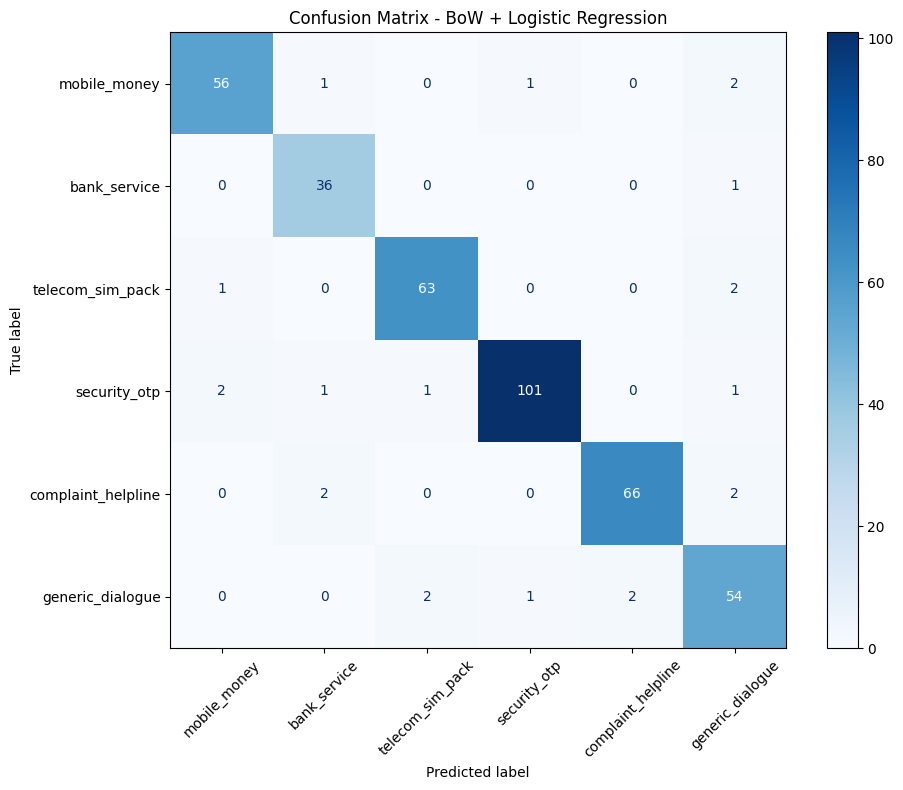

In [144]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_labels = [
    "mobile_money",
    "bank_service",
    "telecom_sim_pack",
    "security_otp",
    "complaint_helpline",
    "generic_dialogue"
]

cm = confusion_matrix(
    grouped_y_test,
    grouped_predictions,
    labels=class_labels
)

fig, ax = plt.subplots(figsize=(10, 8))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Confusion Matrix - BoW + Logistic Regression")
plt.tight_layout()
plt.show()


In [145]:

error_analysis = test_df[
    ["sentence", "label"]
].copy()

error_analysis["predicted_label"] = grouped_predictions

error_analysis = error_analysis[
    error_analysis["label"] != error_analysis["predicted_label"]
].copy()

print("Total test sentences:", len(test_df))
print("Incorrect predictions:", len(error_analysis))
print(
    "Error percentage:",
    round(len(error_analysis) / len(test_df) * 100, 2),
    "%"
)

print("\nFirst 15 classification errors:")

display(error_analysis.head(15))

print("\nMost common actual vs predicted errors:")

error_pairs = (
    error_analysis.groupby(
        ["label", "predicted_label"]
    )
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(error_pairs.head(15))


Total test sentences: 398
Incorrect predictions: 22
Error percentage: 5.53 %

First 15 classification errors:


,sentence,label,predicted_label
32,আপনার গ্রামীণফোন অনুরোধ গ্রহণ করা হয়েছে।,generic_dialogue,telecom_sim_pack
120,"ধন্যবাদ, এটিএম বুথের অবস্থান বললে আমরা নিকটস্থ...",complaint_helpline,bank_service
442,"ধন্যবাদ, আপনি কি লাইভ চ্যাট থেকে আমাদের সাথে য...",generic_dialogue,complaint_helpline
528,রকেটের সাথে থাকার জন্য ধন্যবাদ।,mobile_money,generic_dialogue
599,"বুঝতে পারছি, জাতীয় পরিচয়পত্রের নামের সাথে অ্...",security_otp,bank_service
742,আপনি কি এসএমএস থেকে আমাদের সাথে যোগাযোগ করছেন?,generic_dialogue,complaint_helpline
857,"দুঃখিত, আপনার বিকাশ অ্যাকাউন্ট সাময়িকভাবে লক ...",security_otp,mobile_money
1029,"ঠিক আছে, আপনি কি শাখা থেকে আমাদের সাথে যোগাযোগ...",complaint_helpline,bank_service
1128,"দুঃখিত, আপনি কি কলে থাকতে পারবেন, নাকি আমরা আপ...",complaint_helpline,generic_dialogue
1288,আপনি কি নমিনি তথ্য আপডেট করতে চান?,bank_service,generic_dialogue



Most common actual vs predicted errors:


,label,predicted_label,count
1,complaint_helpline,bank_service,2
2,complaint_helpline,generic_dialogue,2
3,generic_dialogue,complaint_helpline,2
5,generic_dialogue,telecom_sim_pack,2
13,telecom_sim_pack,generic_dialogue,2
11,security_otp,mobile_money,2
7,mobile_money,generic_dialogue,2
6,mobile_money,bank_service,1
4,generic_dialogue,security_otp,1
0,bank_service,generic_dialogue,1


In [146]:

import numpy as np
import pandas as pd

feature_names = grouped_vectorizer.get_feature_names_out()
class_names = grouped_model.classes_

informative_words = []

for class_index, class_name in enumerate(class_names):

    coefficients = grouped_model.coef_[class_index]

    top_indices = np.argsort(coefficients)[-10:][::-1]

    for index in top_indices:
        informative_words.append({
            "Class": class_name,
            "Word": feature_names[index],
            "Coefficient": round(coefficients[index], 4)
        })

informative_df = pd.DataFrame(informative_words)

print("Top 10 Informative Words per Class")
display(informative_df)


Top 10 Informative Words per Class


,Class,Word,Coefficient
0,bank_service,ব্যাংক,3.7640
1,bank_service,কিস্তি,2.4323
2,bank_service,শাখা,2.3849
3,bank_service,কার্ড,2.3570
4,bank_service,চেক,2.2709
5,bank_service,এটিএম,1.8473
6,bank_service,ব্যাংকের,1.7522
7,bank_service,ডিপিএস,1.7303
8,bank_service,চান,1.4937
9,bank_service,বুথ,1.4631


In [151]:

import numpy as np
import pandas as pd

# Get the vocabulary from your existing trained model
feature_names = grouped_vectorizer.get_feature_names_out()
class_names = grouped_model.classes_

top_words = []

for class_index, class_name in enumerate(class_names):
    coefficients = grouped_model.coef_[class_index]

    top_indices = np.argsort(coefficients)[-10:][::-1]

    for index in top_indices:
        top_words.append({
            "Class": class_name,
            "Word": feature_names[index],
            "Coefficient": round(coefficients[index], 4)
        })

top_words_df = pd.DataFrame(top_words)

display(top_words_df)


,Class,Word,Coefficient
0,bank_service,ব্যাংক,3.7640
1,bank_service,কিস্তি,2.4323
2,bank_service,শাখা,2.3849
3,bank_service,কার্ড,2.3570
4,bank_service,চেক,2.2709
5,bank_service,এটিএম,1.8473
6,bank_service,ব্যাংকের,1.7522
7,bank_service,ডিপিএস,1.7303
8,bank_service,চান,1.4937
9,bank_service,বুথ,1.4631


In [152]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shutil

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Create results folder
results_folder = "/content/final_experiment_results"
os.makedirs(results_folder, exist_ok=True)

# A. Save validation comparison
final_validation_comparison.to_csv(
    f"{results_folder}/validation_model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

# B. Save grouped test classification report
class_order = EXPECTED_CLASSES

report_dict = classification_report(
    grouped_y_test,
    grouped_predictions,
    labels=class_order,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(
    f"{results_folder}/grouped_test_classification_report.csv",
    encoding="utf-8-sig"
)

# C. Save confusion matrix as CSV
cm = confusion_matrix(
    grouped_y_test,
    grouped_predictions,
    labels=class_order
)

cm_df = pd.DataFrame(
    cm,
    index=class_order,
    columns=class_order
)

cm_df.index.name = "Actual Label"
cm_df.columns.name = "Predicted Label"

cm_df.to_csv(
    f"{results_folder}/grouped_test_confusion_matrix.csv",
    encoding="utf-8-sig"
)

# D. Save confusion matrix as PNG
fig, ax = plt.subplots(figsize=(10, 8))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_order
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

ax.set_title("BoW + Logistic Regression (C=5)")
plt.tight_layout()

plt.savefig(
    f"{results_folder}/grouped_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# E. Save informative words
top_words_df.to_csv(
    f"{results_folder}/top_10_informative_words_per_class.csv",
    index=False,
    encoding="utf-8-sig"
)

# F. Save misclassified sentences
error_df = test_df.reset_index(drop=True).copy()

error_df["actual_label"] = grouped_y_test
error_df["predicted_label"] = grouped_predictions

misclassified_df = error_df[
    error_df["actual_label"] != error_df["predicted_label"]
].copy()

misclassified_df.to_csv(
    f"{results_folder}/misclassified_test_sentences.csv",
    index=False,
    encoding="utf-8-sig"
)

# G. Save experiment summary
correct = np.sum(
    np.array(grouped_y_test) == np.array(grouped_predictions)
)

summary = f"""
FINAL EXPERIMENT SUMMARY

Dataset size: 2682
Number of classes: 6
Feature representation: BoW Unigram
Classifier: Logistic Regression
C: 5

Grouped test samples: {len(grouped_y_test)}
Correct predictions: {correct}
Incorrect predictions: {len(misclassified_df)}
Error percentage: {len(misclassified_df) / len(grouped_y_test) * 100:.2f}%

Accuracy: {report_dict['accuracy']:.4f}
Macro Precision: {report_dict['macro avg']['precision']:.4f}
Macro Recall: {report_dict['macro avg']['recall']:.4f}
Macro F1: {report_dict['macro avg']['f1-score']:.4f}
"""

with open(
    f"{results_folder}/experiment_summary.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(summary)

# H. Create ZIP
zip_path = shutil.make_archive(
    "/content/final_experiment_results",
    "zip",
    results_folder
)

print("Experiment results saved!")
print("\nFiles:")

for filename in sorted(os.listdir(results_folder)):
    print(filename)

print("\nZIP exists:", os.path.exists(zip_path))
print("ZIP size:", round(os.path.getsize(zip_path) / 1024, 2), "KB")


Experiment results saved!

Files:
experiment_summary.txt
grouped_test_classification_report.csv
grouped_test_confusion_matrix.csv
grouped_test_confusion_matrix.png
misclassified_test_sentences.csv
top_10_informative_words_per_class.csv
validation_model_comparison.csv

ZIP exists: True
ZIP size: 193.21 KB


In [153]:
from google.colab import files

files.download("/content/final_experiment_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [154]:
for name in [
    "random_y_test",
    "random_predictions",
    "random_model",
    "random_vectorizer",
    "random_test_df"
]:
    print(name, ":", "Available" if name in globals() else "Missing")

random_y_test : Available
random_predictions : Available
random_model : Available
random_vectorizer : Available
random_test_df : Available


In [155]:

import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Main folder
base_folder = "/content/final_experiment_results"

folders = {
    "validation": f"{base_folder}/validation",
    "random": f"{base_folder}/random_split",
    "grouped": f"{base_folder}/group_based_split",
    "words": f"{base_folder}/informative_words"
}

for folder in folders.values():
    os.makedirs(folder, exist_ok=True)


# Function to save one experiment's results
def save_experiment_results(
    y_true,
    y_pred,
    test_data,
    folder,
    experiment_name
):
    class_order = EXPECTED_CLASSES

    # Classification report
    report = classification_report(
        y_true,
        y_pred,
        labels=class_order,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    report_df.to_csv(
        f"{folder}/classification_report.csv",
        encoding="utf-8-sig"
    )

    # Confusion matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_order
    )

    cm_df = pd.DataFrame(
        cm,
        index=class_order,
        columns=class_order
    )

    cm_df.index.name = "Actual Label"
    cm_df.columns.name = "Predicted Label"

    cm_df.to_csv(
        f"{folder}/confusion_matrix.csv",
        encoding="utf-8-sig"
    )

    # Confusion matrix image
    fig, ax = plt.subplots(figsize=(10, 8))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_order
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        values_format="d"
    )

    ax.set_title(experiment_name)
    plt.tight_layout()

    plt.savefig(
        f"{folder}/confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    # Misclassified sentences
    errors = test_data.reset_index(drop=True).copy()

    errors["actual_label"] = list(y_true)
    errors["predicted_label"] = list(y_pred)

    errors = errors[
        errors["actual_label"] != errors["predicted_label"]
    ]

    errors.to_csv(
        f"{folder}/misclassified_sentences.csv",
        index=False,
        encoding="utf-8-sig"
    )

    return report


# 1. Save group-based experiment
grouped_report = save_experiment_results(
    grouped_y_test,
    grouped_predictions,
    test_df,
    folders["grouped"],
    "Final Group-Based Split"
)


# 2. Save random-split experiment
random_report = save_experiment_results(
    random_y_test,
    random_predictions,
    random_test_df,
    folders["random"],
    "Random Split"
)


# 3. Save validation comparison
final_validation_comparison.to_csv(
    f"{folders['validation']}/validation_model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)


# 4. Save informative words
top_words_df.to_csv(
    f"{folders['words']}/top_10_informative_words_per_class.csv",
    index=False,
    encoding="utf-8-sig"
)


# 5. Save side-by-side summary
summary_df = pd.DataFrame([
    {
        "Split": "Random",
        "Test Samples": len(random_y_test),
        "Accuracy": random_report["accuracy"],
        "Macro Precision": random_report["macro avg"]["precision"],
        "Macro Recall": random_report["macro avg"]["recall"],
        "Macro F1": random_report["macro avg"]["f1-score"]
    },
    {
        "Split": "Final Group-Based",
        "Test Samples": len(grouped_y_test),
        "Accuracy": grouped_report["accuracy"],
        "Macro Precision": grouped_report["macro avg"]["precision"],
        "Macro Recall": grouped_report["macro avg"]["recall"],
        "Macro F1": grouped_report["macro avg"]["f1-score"]
    }
])

summary_df.to_csv(
    f"{base_folder}/random_vs_grouped_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

summary_df.to_string(
    buf=open(f"{base_folder}/experiment_summary.txt", "w", encoding="utf-8")
)

# 6. Create ZIP
zip_path = shutil.make_archive(
    "/content/final_experiment_results",
    "zip",
    base_folder
)

print("Both experiments saved successfully!")
print("\nComparison:")
display(summary_df)

print("\nSaved files:")
for root, dirs, files_list in os.walk(base_folder):
    for filename in sorted(files_list):
        print(os.path.relpath(
            os.path.join(root, filename),
            base_folder
        ))

print("\nZIP created:", os.path.exists(zip_path))
print("ZIP size:", round(os.path.getsize(zip_path) / 1024, 2), "KB")


Both experiments saved successfully!

Comparison:


,Split,Test Samples,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Random,403,0.965261,0.961593,0.965338,0.963090
1,Final Group-Based,398,0.944724,0.937639,0.945299,0.941063



Saved files:
experiment_summary.txt
grouped_test_classification_report.csv
grouped_test_confusion_matrix.csv
grouped_test_confusion_matrix.png
misclassified_test_sentences.csv
random_vs_grouped_comparison.csv
top_10_informative_words_per_class.csv
validation_model_comparison.csv
validation/validation_model_comparison.csv
informative_words/top_10_informative_words_per_class.csv
group_based_split/classification_report.csv
group_based_split/confusion_matrix.csv
group_based_split/confusion_matrix.png
group_based_split/misclassified_sentences.csv
random_split/classification_report.csv
random_split/confusion_matrix.csv
random_split/confusion_matrix.png
random_split/misclassified_sentences.csv

ZIP created: True
ZIP size: 561.59 KB


In [156]:
from google.colab import files
files.download("/content/final_experiment_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Keyword Rule Agreement with Final Gold Labels

In [157]:

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)

# Keyword rules documented in the Member 3 error-analysis notebook
RULES = [
    ("security_otp", [
        "ওটিপি", "নিরাপত্তা যাচাই", "পিন",
        "পাসওয়ার্ড", "ভেরিফিকেশন"
    ]),
    ("complaint_helpline", [
        "অভিযোগ", "হেল্পলাইন", "কাস্টমার কেয়ার", "ফিডব্যাক"
    ]),
    ("bank_service", [
        "ব্যাংক", "কার্ড", "ডিপিএস", "কিস্তি",
        "লোন", "ঋণ"
    ]),
    ("telecom_sim_pack", [
        "সিম", "প্যাক", "ইন্টারনেট", "ডেটা",
        "মিনিট", "নেটওয়ার্ক", "এসএমএস"
    ]),
    ("mobile_money", [
        "রকেট", "বিকাশ", "নগদ", "ক্যাশ",
        "লেনদেন", "পেমেন্ট", "ব্যালেন্স", "টাকা", "রিফান্ড"
    ])
]

# Assign a keyword-rule label.
# Priority follows the order of RULES above.
def keyword_label(sentence):
    sentence = str(sentence)

    for class_name, keywords in RULES:
        for keyword in keywords:
            if keyword in sentence:
                return class_name

    return "generic_dialogue"


# Apply keyword rules to all sentences
keyword_data = m2_data[
    ["sentence_id", "sentence", "label"]
].copy()

keyword_data["keyword_label"] = (
    keyword_data["sentence"].apply(keyword_label)
)

# Compare keyword labels with final gold labels
y_true = keyword_data["label"]
y_keyword = keyword_data["keyword_label"]

accuracy = accuracy_score(y_true, y_keyword)
kappa = cohen_kappa_score(y_true, y_keyword)

print("Total sentences:", len(keyword_data))
print("Keyword-rule accuracy:", round(accuracy, 4))
print("Keyword-rule agreement:", f"{accuracy * 100:.2f}%")
print("Cohen's Kappa:", round(kappa, 4))

print("\nKeyword label distribution:")
print(keyword_data["keyword_label"].value_counts())

print("\nFinal gold label distribution:")
print(keyword_data["label"].value_counts())


Total sentences: 2682
Keyword-rule accuracy: 0.7435
Keyword-rule agreement: 74.35%
Cohen's Kappa: 0.6925

Keyword label distribution:
keyword_label
generic_dialogue      896
mobile_money          453
security_otp          376
complaint_helpline    343
telecom_sim_pack      340
bank_service          274
Name: count, dtype: int64

Final gold label distribution:
label
security_otp          574
mobile_money          512
telecom_sim_pack      511
generic_dialogue      397
complaint_helpline    377
bank_service          311
Name: count, dtype: int64


In [158]:

# Class-wise agreement report
print("CLASSIFICATION REPORT: KEYWORD RULES VS FINAL GOLD")

keyword_report = classification_report(
    y_true,
    y_keyword,
    labels=EXPECTED_CLASSES,
    output_dict=True,
    zero_division=0
)

keyword_report_df = pd.DataFrame(keyword_report).transpose()

display(keyword_report_df.round(4))

# Confusion matrix
keyword_cm = confusion_matrix(
    y_true,
    y_keyword,
    labels=EXPECTED_CLASSES
)

keyword_cm_df = pd.DataFrame(
    keyword_cm,
    index=EXPECTED_CLASSES,
    columns=EXPECTED_CLASSES
)

keyword_cm_df.index.name = "Actual Gold Label"
keyword_cm_df.columns.name = "Keyword Predicted Label"

display(keyword_cm_df)

# Save sentence-level comparison
keyword_data["agreement"] = (
    keyword_data["label"] == keyword_data["keyword_label"]
)

keyword_data.to_csv(
    "/content/keyword_vs_gold_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

keyword_cm_df.to_csv(
    "/content/keyword_vs_gold_confusion_matrix.csv",
    encoding="utf-8-sig"
)

keyword_report_df.to_csv(
    "/content/keyword_vs_gold_classification_report.csv",
    encoding="utf-8-sig"
)

# Show disagreements
disagreements = keyword_data[
    keyword_data["agreement"] == False
].copy()

print("\nTotal disagreements:", len(disagreements))

display(disagreements.head(20))

print("\nSaved three comparison CSV files.")


CLASSIFICATION REPORT: KEYWORD RULES VS FINAL GOLD


,precision,recall,f1-score,support
mobile_money,0.7859,0.6953,0.7378,512.0000
bank_service,0.9708,0.8553,0.9094,311.0000
telecom_sim_pack,0.8824,0.5871,0.7051,511.0000
security_otp,1.0000,0.6551,0.7916,574.0000
complaint_helpline,0.9854,0.8966,0.9389,377.0000
generic_dialogue,0.3996,0.9018,0.5538,397.0000
accuracy,0.7435,0.7435,0.7435,0.7435
macro avg,0.8373,0.7652,0.7727,2682.0000
weighted avg,0.8424,0.7435,0.7640,2682.0000


Keyword Predicted Label,mobile_money,bank_service,telecom_sim_pack,security_otp,complaint_helpline,generic_dialogue
Actual Gold Label,,,,,,
mobile_money,356,0,17,0,1,138
bank_service,11,266,0,0,0,34
telecom_sim_pack,60,0,300,0,0,151
security_otp,9,8,0,376,0,181
complaint_helpline,0,0,5,0,338,34
generic_dialogue,17,0,18,0,4,358



Total disagreements: 688


,sentence_id,sentence,label,keyword_label,agreement
3,S0004,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,mobile_money,generic_dialogue,False
9,S0010,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,mobile_money,generic_dialogue,False
10,S0011,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,mobile_money,generic_dialogue,False
18,S0019,"দুঃখিত, আপনি কি এসএমএস থেকে আমাদের সাথে যোগাযো...",complaint_helpline,telecom_sim_pack,False
21,S0022,আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি শুনে রাখু...,mobile_money,generic_dialogue,False
31,S0032,"বুঝতে পারছি, আপনার লাস্ট সেন্ড মানি রিসিভারের ...",mobile_money,generic_dialogue,False
34,S0035,"চিন্তা করবেন না, অ্যাপের ক্যাশ পরিষ্কার করার প...",generic_dialogue,mobile_money,False
37,S0038,"আপনার তথ্যের জন্য ধন্যবাদ, আপনার সমস্যা কি চেক...",bank_service,generic_dialogue,False
40,S0041,"ঠিক আছে, আপনার ট্রানজ্যাকশন রেফারেন্স নম্বরটি ...",mobile_money,generic_dialogue,False
47,S0048,"আপনার তথ্যের জন্য ধন্যবাদ, আপনার কলব্যাক অনুরো...",complaint_helpline,generic_dialogue,False



Saved three comparison CSV files.
